# Proyecto Final — Prediccion de sobrecostos en inversion publica del Peru (MEF)
**Curso:** IN5306 - Applied Machine Learning — Ciclo 9 | **Docente:** Villavicencio Antunez, Jorge

Marco de trabajo: **CRISP-DM** (visto en clase, Semanas 1-4)

Business Understanding → Data Understanding → **Data Preparation** → Modeling → Evaluation → Deployment

## 1. Business Understanding (Entendimiento del negocio)

### 1.1 Problematica

El Estado peruano no cuenta con herramientas preventivas para anticipar, al momento de aprobar una obra publica, cuanto podria desviarse su costo final respecto al presupuesto inicial aprobado. Esta brecha entre lo planificado y lo ejecutado genera ineficiencia en el gasto estatal, obras paralizadas y sobrecostos que afectan directamente a la poblacion. Un modelo que estime el porcentaje de sobrecosto esperado a partir de las caracteristicas iniciales de la obra permite priorizar la supervision y mejorar la asignacion de recursos.

### 1.2 Contexto

El Ministerio de Economia y Finanzas (MEF) publica en su Portal de Datos Abiertos el dataset 'Detalle de Inversiones' con informacion de todas las inversiones registradas en el sistema Invierte.pe: montos, ubicacion geografica, funcion, modalidad de ejecucion, avances y fechas. Es una fuente de datos real, publica y actualizada que cubre todo el Peru.

### 1.3 Objetivos del proyecto

**1.3.1 Objetivo general:**
Desarrollar y comparar modelos de Machine Learning que predigan el porcentaje de desviacion presupuestal (sobrecosto) de un proyecto de inversion publica a partir de sus caracteristicas iniciales.

**1.3.2 Objetivos especificos:**
- Adquirir los datos del MEF mediante su API de Datos Abiertos y documentar su estructura.
- Realizar un analisis exploratorio para identificar patrones de sobrecosto por sector, region, modalidad y tipologia.
- Preparar los datos (limpieza, outliers, encoding, escalado) evitando fuga de informacion.
- Comparar al menos 4 modelos de regresion y justificar el mejor usando metricas apropiadas.
- Comunicar hallazgos accionables para la prevencion de sobrecostos en obras publicas.

### 1.4 Que se predice (variable objetivo Y)

**Porcentaje de desviacion presupuestal:** (COSTO_ACTUALIZADO - MONTO_VIABLE) / MONTO_VIABLE * 100

Se elige la desviacion y no el costo actualizado porque predecir el costo final desde el monto inicial seria casi trivial (ambos estan altamente correlacionados). La desviacion captura exactamente el sobrecosto que queremos prevenir.

### 1.5 Tipo de problema de Machine Learning

**Regresion supervisada.** Se predice un valor numerico continuo (porcentaje de sobrecosto) a partir de caracteristicas iniciales de la obra.

> **Advertencia de fuga de informacion (data leakage):** variables como AVANCE_FISICO, AVANCE_EJECUCION, DEV_ANIO_ACTUAL o SALDO_EJECUTAR solo se conocen durante o despues de la ejecucion de la obra. Incluirlas como predictores destruiria el objetivo preventivo del modelo.

## 2. Carga de datos y librerias

In [1]:
#Importar librerias
import pandas as pd


In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import time
import os

pd.set_option('display.max_columns', None)

# Estilo visual consistente para todos los graficos del notebook
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

def etiqueta_corta(texto, ancho=30):
    # Recorta etiquetas largas para que no desborden los graficos en grilla
    texto = str(texto)
    return texto if len(texto) <= ancho else texto[:ancho - 1] + '...'

### 2.1 Adquisicion de datos

**2.1.1 Descripcion clara de la fuente de datos utilizada**

Los datos fueron obtenidos del Portal de Datos Abiertos del Ministerio de Economia y Finanzas del Peru (datosabiertos.mef.gob.pe), dataset 'Detalle de Inversiones' del sistema Invierte.pe, disponible bajo licencia abierta. Se accede a traves de la API publica `datastore_search` que permite descarga paginada sin autenticacion.

**2.1.2 Cantidad de datasets involucrados**

Se trabaja con un unico dataset principal: `inversiones_mef.csv`, que consolida todos los proyectos de inversion publica del Peru registrados en el sistema Invierte.pe.

**2.1.3 Diccionario de datos (variables principales)**

| Codigo | Nombre propuesto | Descripcion | Rol |
|---|---|---|---|
| CODIGO_UNICO | id_proyecto | Identificador unico del proyecto (CUI) | Llave |
| NOMBRE_INVERSION | nombre | Nombre del proyecto | Descriptivo |
| NIVEL | nivel_gobierno | Nivel jerarquico: GN/GR/GL | Predictor |
| SECTOR | sector | Ministerio o rubro | Predictor |
| FUNCION | funcion | Funcion publica (Saneamiento, Transporte...) | Predictor |
| DES_TIPOLOGIA | tipologia | Tipo especifico de obra | Predictor |
| TIPO_INVERSION | tipo_inversion | Tipo de inversion | Predictor |
| DES_MODALIDAD | modalidad | Contrata / Administracion directa | Predictor |
| DEPARTAMENTO | departamento | Region politica | Predictor |
| PROVINCIA | provincia | Provincia | Predictor |
| MONTO_VIABLE | monto_viable | Presupuesto inicial aprobado (S/.) | Predictor |
| COSTO_ACTUALIZADO | costo_actual | Costo final o actual (S/.) | Base del objetivo Y |
| FEC_INI_EJECUCION | fecha_ini | Fecha de inicio de ejecucion | Feature engineering |
| FEC_FIN_EJECUCION | fecha_fin | Fecha estimada de fin | Feature engineering |
| FECHA_VIABILIDAD | fecha_viab | Fecha de viabilidad del proyecto | Feature engineering |
| LATITUD / LONGITUD | lat / lon | Coordenadas geograficas | Analisis espacial |
| EXPEDIENTE_TECNICO | exp_tecnico | Cuenta con expediente tecnico | Predictor |
| AVANCE_FISICO | avance_fis | Avance fisico de la obra | **Excluir (fuga)** |
| AVANCE_EJECUCION | avance_eje | Porcentaje de dinero pagado | **Excluir (fuga)** |

In [3]:
RID = 'f9cc4ba0-931a-4b70-86c9-eacbd8c68596'
BASE = 'https://api.datosabiertos.mef.gob.pe/DatosAbiertos/v1/datastore_search'

def descargar_mef(resource_id=RID, limite=10000, max_reintentos=4, pausa=3):
    registros, offset, total = [], 0, None
    while True:
        params = {'resource_id': resource_id, 'limit': limite, 'offset': offset}
        data = None
        for intento in range(max_reintentos):
            try:
                r = requests.get(BASE, params=params, timeout=90)
                r.raise_for_status()
                data = r.json()
                break
            except Exception as e:
                print('  reintento', intento + 1, '->', e)
                time.sleep(pausa)
        if data is None:
            raise RuntimeError('Fallo en offset ' + str(offset))
        recs = data.get('records', [])
        if total is None:
            total = int(data['result'].get('include_total', 0))
            print('Total registros:', format(total, ','))
        if not recs:
            break
        registros.extend(recs)
        print('  descargados', format(len(registros), ','), '/', format(total, ','))
        offset += limite
        if len(registros) >= total:
            break
    return pd.DataFrame(registros)

In [4]:
# ============================================================
# Snapshot FIJO de los datos del MEF (version congelada).
# Este notebook YA NO llama a la API del MEF. Siempre descarga
# el MISMO archivo desde un enlace publico y estable de Drive
# que nosotros controlamos. Asi, cualquier persona que corra
# este notebook -en cualquier computadora, en cualquier momento-
# obtiene exactamente los mismos datos, aunque el MEF actualice
# su base despues. La funcion descargar_mef() de arriba queda
# solo como documentacion de como se obtuvo el snapshot original;
# ya NO se invoca automaticamente en este pipeline.
# ============================================================
!pip install -q gdown
import gdown

FILE_ID = '19xYE2ppcFlMoX6g6Ni6BXBqV7hIL5EiG'
ARCHIVO = 'inversiones_mef_snapshot.csv'

if not os.path.exists(ARCHIVO):
    gdown.download(id=FILE_ID, output=ARCHIVO, quiet=False)

df = pd.read_csv(ARCHIVO, dtype=str)
print('Snapshot fijo cargado (mismo archivo siempre, sin llamadas al MEF):', df.shape)
df.head()

Downloading...
From (original): https://drive.google.com/uc?id=19xYE2ppcFlMoX6g6Ni6BXBqV7hIL5EiG
From (redirected): https://drive.google.com/uc?id=19xYE2ppcFlMoX6g6Ni6BXBqV7hIL5EiG&confirm=t&uuid=474f4fd4-f5df-4399-98f5-bb7f23e00d66
To: /content/inversiones_mef_snapshot.csv
100%|██████████| 226M/226M [00:06<00:00, 33.3MB/s]


Snapshot fijo cargado (mismo archivo siempre, sin llamadas al MEF): (150020, 68)


,ULTIMO_DEVENGADO,PRIMER_DEVENGADO,PROVINCIA,NOMBRE_UEI,TIENE_F9,PMI_ANIO_3,MONTO_LAUDO,NOMBRE_INVERSION,MONTO_FIANZA,ETAPA_F8,LATITUD,AVANCE_EJECUCION,PMI_ANIO_2,UBIGEO,NOMBRE_OPMI,FUNCION,TIPO_INVERSION,PIA_ANIO_ACTUAL,DISTRITO,AVANCE_FISICO,SECTOR,DEV_ANIO_ACTUAL,DES_TIPOLOGIA,MONTO_ET_F8,PMI_ANIO_4,SEC_EJEC,SUBPROGRAMA,SITUACION,COMPROM_ANUAL_ANIO_ACTUAL,ENTIDAD,TIENE_AVAN_FISICO,NUM_HABITANTES_BENEF,REGISTRADO_PMI,PROGRAMA,CODIGO_SNIP,DEVEN_ACUMUL_ANIO_ANT,NOMBRE_UEP,EXPEDIENTE_TECNICO,FEC_REG_F9,NIVEL,MONTO_VIABLE,PMI_ANIO_1,COSTO_ACTUALIZADO,FECHA_VIABILIDAD,FEC_INI_EJECUCION,INFORME_CIERRE,SALDO_EJECUTAR,DEPARTAMENTO,FEC_FIN_EJEC_FISICA,NOMBRE_UF,FECHA_REGISTRO,CODIGO_UNICO,LONGITUD,ALTERNATIVA,ULT_FEC_DECLA_ESTIM,FEC_INI_EJEC_FISICA,TIENE_F12B,ANIO_PROCESO,FEC_FIN_EJECUCION,TIENE_F8,CERTIF_ANIO_ACTUAL,DES_MODALIDAD,ETAPA_F9,ESTADO,CTRL_CONCURR,PIM_ANIO_ACTUAL,MARCO,IND_IOARR_EMERG
0,202607,202602,URUBAMBA,UEI DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAYT...,NO,0.0,0.0,MEJORAMIENTO DEL SERVICIO DE PROVISIÓN DE AGUA...,0.0,NaN,-13.233869415294627,0.0,0.0,081306,OPMI DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAY...,AGROPECUARIA,PROYECTO DE INVERSION,0.0,OLLANTAYTAMBO,NaN,GOBIERNOS LOCALES,60911.14,RIEGO TECNIFICADO,NaN,0.0,300790,RIEGO TECNIFICADO,VIABLE,60911.14,MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,NO,2035,SI,RIEGO,2716769,0.0,MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,NO,NaN,GL,1853953.5,59928.0,1853953.5,2026-01-09 00:00:00,2026-03-01 00:00:00,NO,1793041.5,CUSCO,NaN,UF DE LA MUNICIPALIDAD DISTRITAL DE OLLANTAYTAMBO,2025-12-29 00:00:00,2716769,-72.22036089385871,El recurso hídrico se captará de los rios de ...,NaN,NaN,SI,2026,2026-09-01 00:00:00,NO,60911.14,ADMINISTRACIÓN DIRECTA,NaN,ACTIVO,0.0,60912,INVIERTE,NO
1,202609,202310,HUARI,UEI DE LA MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,NO,0.0,0.0,MEJORAMIENTO DEL SERVICIO DE TRANSITABILIDAD V...,0.0,Ejecución física (C),-9.65149380947185,52.01,0.0,021004,OPMI DE LA MUNICIPALIDAD DISTRITAL DE SAN MARCOS,TRANSPORTE,PROYECTO DE INVERSION,0.0,CHAVIN DE HUANTAR,50.9,GOBIERNOS LOCALES,359855.69,CARRETERAS VECINALES,12861187.23,0.0,350070,VÍAS VECINALES,VIABLE,370879.42,MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,SI,931,SI,TRANSPORTE TERRESTRE,2565175,11518774.28,MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA - MMCDM,SI,NaN,GL,11950887.0,2962094.0,14365540.91,2022-10-25 00:00:00,2022-03-06 00:00:00,NO,359973.05,ANCASH,2024-06-11 00:00:00,UF DE LA MANCOMUNIDAD MUNICIPAL CUENCA DEL MOSNA,2022-10-23 00:00:00,2565175,-77.19092433890556,PRODUCTO N 01 ADECUADA INFRAESTRUCTURA PARA EL...,2026-05-22 16:20:37,2023-10-16 00:00:00,SI,2026,2026-12-31 00:00:00,SI,2357221.63,"ADMINISTRACIÓN INDIRECTA - POR CONTRATA,ADMINI...",NaN,ACTIVO,115327.42,2602121,INVIERTE,NO
2,NaN,NaN,LA CONVENCION,UEI DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,0.0,RENOVACION DE PUENTE PEATONAL EN EL(LA) REY DE...,0.0,NaN,-12.538953,0.0,NaN,080910,OPMI DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,TRANSPORTE,INVERSIONES IOARR,NaN,PICHARI,NaN,GOBIERNOS LOCALES,0.0,CAMINOS DE HERRADURA,NaN,NaN,300757,CAMINOS DE HERRADURA,APROBADO,NaN,MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,NO,TRANSPORTE TERRESTRE,2721653,0.0,MUNICIPALIDAD DISTRITAL DE PICHARI,NO,NaN,GL,1101000.0,NaN,1101000.0,2026-02-19 00:00:00,2026-04-01 00:00:00,NO,1101000.0,CUSCO,NaN,UF DE LA MUNICIPALIDAD DISTRITAL DE PICHARI,2026-02-19 00:00:00,2721653,-73.780939,NaN,NaN,NaN,SI,2026,2026-09-30 00:00:00,NO,NaN,ADMINISTRACIÓN DIRECTA,NaN,ACTIVO,0.0,0,INVIERTE,NO
3,NaN,NaN,PACHITEA,UEI GERENCIA REGIONAL DE DESARROLLO SOCIAL,NO,NaN,0.0,"ADQUISICION DE UNIDAD MOVIL, ANALIZADOR BIOQUI...",0.0,NaN,-9.896793840843099,NaN,NaN,100801,OPMI DEL GOBIERNO REGIONAL HUANUCO,SALUD,INVERSIONES IOARR,NaN,PANAO,NaN,GOBIERNOS REGIONALES,0.0,ESTABLECIMIENTOS DE SALUD DEL PRIMER NIVEL DE ...,NaN,NaN,804,ATENCIÓN MÉDICA BÁSICA,APROBADO,NaN,GOBIERNO REGIONAL HUANUCO,NO,NaN,NO,SALUD INDIVIDUAL,2708661,0.0,REGION HUANUCO-SEDE CENTRAL,NO,NaN,GR,1843733.33,NaN,1843733.33,2026-01-08 00:00:00,2025-11-01 00:0

## 3. Data Understanding (Entendimiento de los datos)

### 3.1 Dimension

In [5]:
df.shape

(150020, 68)

### 3.2 Tipos de datos

In [6]:
df.dtypes

,0
ULTIMO_DEVENGADO,object
PRIMER_DEVENGADO,object
PROVINCIA,object
NOMBRE_UEI,object
TIENE_F9,object
...,...
ESTADO,object
CTRL_CONCURR,object
PIM_ANIO_ACTUAL,object
MARCO,object


### 3.3 Informacion general

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150020 entries, 0 to 150019
Data columns (total 68 columns):
 #   Column                     Non-Null Count   Dtype 
---  ------                     --------------   ----- 
 0   ULTIMO_DEVENGADO           95037 non-null   object
 1   PRIMER_DEVENGADO           95037 non-null   object
 2   PROVINCIA                  149938 non-null  object
 3   NOMBRE_UEI                 146879 non-null  object
 4   TIENE_F9                   150020 non-null  object
 5   PMI_ANIO_3                 57317 non-null   object
 6   MONTO_LAUDO                150020 non-null  object
 7   NOMBRE_INVERSION           150018 non-null  object
 8   MONTO_FIANZA               150020 non-null  object
 9   ETAPA_F8                   118692 non-null  object
 10  LATITUD                    149526 non-null  object
 11  AVANCE_EJECUCION           109959 non-null  object
 12  PMI_ANIO_2                 57316 non-null   object
 13  UBIGEO                     149791 non-null  

### 3.4 Conversion de columnas numericas

La API entrega todos los campos como texto. Convertimos las columnas numericas para habilitar el analisis estadistico.

In [8]:
cols_numericas = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'AVANCE_FISICO', 'AVANCE_EJECUCION',
                  'PIA_ANIO_ACTUAL', 'PIM_ANIO_ACTUAL', 'DEV_ANIO_ACTUAL', 'SALDO_EJECUTAR',
                  'LATITUD', 'LONGITUD']
for c in cols_numericas:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print('Tipos tras conversion:')
df[cols_numericas].dtypes

Tipos tras conversion:


,0
MONTO_VIABLE,float64
COSTO_ACTUALIZADO,float64
AVANCE_FISICO,float64
AVANCE_EJECUCION,float64
PIA_ANIO_ACTUAL,float64
PIM_ANIO_ACTUAL,int64
DEV_ANIO_ACTUAL,float64
SALDO_EJECUTAR,float64
LATITUD,float64
LONGITUD,float64


### 3.5 Revision de valores faltantes

In [9]:
print('Valores faltantes por columna (top 20):')
df.isna().sum().sort_values(ascending=False).head(40)

Valores faltantes por columna (top 20):


,0
FEC_REG_F9,133918
ETAPA_F9,133918
COMPROM_ANUAL_ANIO_ACTUAL,102651
PIA_ANIO_ACTUAL,102651
CERTIF_ANIO_ACTUAL,102651
PMI_ANIO_1,94353
PMI_ANIO_4,92705
PMI_ANIO_2,92704
PMI_ANIO_3,92703
AVANCE_FISICO,87458


In [10]:
print('Porcentaje de faltantes (%):')
(df.isna().mean() * 100).sort_values(ascending=False).head(20)

Porcentaje de faltantes (%):


,0
FEC_REG_F9,89.266764
ETAPA_F9,89.266764
COMPROM_ANUAL_ANIO_ACTUAL,68.424877
PIA_ANIO_ACTUAL,68.424877
CERTIF_ANIO_ACTUAL,68.424877
PMI_ANIO_1,62.893614
PMI_ANIO_4,61.795094
PMI_ANIO_2,61.794427
PMI_ANIO_3,61.793761
AVANCE_FISICO,58.297560


### 3.6 Estadistica descriptiva

In [11]:
df.describe(include='all')

,ULTIMO_DEVENGADO,PRIMER_DEVENGADO,PROVINCIA,NOMBRE_UEI,TIENE_F9,PMI_ANIO_3,MONTO_LAUDO,NOMBRE_INVERSION,MONTO_FIANZA,ETAPA_F8,LATITUD,AVANCE_EJECUCION,PMI_ANIO_2,UBIGEO,NOMBRE_OPMI,FUNCION,TIPO_INVERSION,PIA_ANIO_ACTUAL,DISTRITO,AVANCE_FISICO,SECTOR,DEV_ANIO_ACTUAL,DES_TIPOLOGIA,MONTO_ET_F8,PMI_ANIO_4,SEC_EJEC,SUBPROGRAMA,SITUACION,COMPROM_ANUAL_ANIO_ACTUAL,ENTIDAD,TIENE_AVAN_FISICO,NUM_HABITANTES_BENEF,REGISTRADO_PMI,PROGRAMA,CODIGO_SNIP,DEVEN_ACUMUL_ANIO_ANT,NOMBRE_UEP,EXPEDIENTE_TECNICO,FEC_REG_F9,NIVEL,MONTO_VIABLE,PMI_ANIO_1,COSTO_ACTUALIZADO,FECHA_VIABILIDAD,FEC_INI_EJECUCION,INFORME_CIERRE,SALDO_EJECUTAR,DEPARTAMENTO,FEC_FIN_EJEC_FISICA,NOMBRE_UF,FECHA_REGISTRO,CODIGO_UNICO,LONGITUD,ALTERNATIVA,ULT_FEC_DECLA_ESTIM,FEC_INI_EJEC_FISICA,TIENE_F12B,ANIO_PROCESO,FEC_FIN_EJECUCION,TIENE_F8,CERTIF_ANIO_ACTUAL,DES_MODALIDAD,ETAPA_F9,ESTADO,CTRL_CONCURR,PIM_ANIO_ACTUAL,MARCO,IND_IOARR_EMERG
count,95037,95037,149938,146879,150020,57317,150020,150018,150020,118692,1.495260e+05,1.099590e+05,57316,149791,143354,150009,150020,4.736900e+04,149927,6.256200e+04,150020,1.500200e+05,121930,111831,57315,150015,150009,150020,47369,150020,150020,103724,150020,150009,150020,150020,149980,150020,16102,150020,1.497790e+05,55667,1.500200e+05,149785,138364,150018,1.500200e+05,149941,106960,145566,150020,149953,1.495260e+05,103644,79539,106960,150020,150020,138367,150020,47369,145211,16102,150020,150020,1.500200e+05,150020,150020
unique,255,272,197,3070,2,7637,1221,150013,139,4,NaN,NaN,15771,2029,1862,31,15,NaN,1738,NaN,35,NaN,224,96336,5081,2590,200,3,26007,2018,2,16165,2,79,150019,73484,2545,2,16092,3,NaN,35369,NaN,6511,5915,1,NaN,26,6868,3308,7025,149952,NaN,100635,79101,5697,2,1,6618,2,29721,128,2,1,11164,NaN,2,2
top,202608,202312,LIMA,GERENCIA REGIONAL DE INFRAESTRUCTURA,NO,0.0,0.0,MEJORAMIENTO Y AMPLIACION DE LOS SERVICIOS DE ...,0.0,Ejecución física (C),NaN,NaN,0.0,021014,OPMI DEL MINISTERIO DE EDUCACION,TRANSPORTE,PROYECTO DE INVERSION,NaN,SAN MARCOS,NaN,GOBIERNOS LOCALES,NaN,CARRETERAS VECINALES,0.0,0.0,300163,VÍAS URBANAS,VIABLE,0.0,"MINISTERIO DE VIVIENDA, CONSTRUCCION Y SANEAMI...",NO,0,NO,SANEAMIENTO,17669,0.0,MUNICIPALIDAD DISTRITAL DE SAN MARCOS,SI,2020-05-21 23:32:33,GL,NaN,0.0,NaN,2020-01-20 00:00:00,2026-07-01 00:00:00,NO,NaN,LIMA,2026-12-31 00:00:00,UF DE LA MUNICIPALIDAD DISTRITAL DE SAN MARCOS,2020-01-15 00:00:00,2022788,NaN,PROGRAMA DE INVERSIÓN,2026-09-03 14:56:50,2026-06-01 00:00:00,SI,2026,2026-12-31 00:00:00,SI,0.0,ADMINISTRACIÓN INDIRECTA - POR CONTRATA,Pendiente de liquidación,ACTIVO,0.0,NaN,INVIERTE,NO
freq,10937,3305,8072,1631,133918,41039,148524,2,149862,89523,NaN,NaN,30731,1340,1888,36125,82468,NaN,1340,NaN,123767,NaN,14007,2592,45153,1327,16666,103948,11666,1853,93703,769,92703,19712,2,63601,1327,100053,2,123767,NaN,8240,NaN,356,2313,150018,NaN,15757,2200,1329,343,2,NaN,166,3,1027,111757,150020,4947,118692,8521,80956,15963,150020,138687,NaN,128604,147143
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-5.147553e+05,8.865514e+03,NaN,NaN,NaN,NaN,NaN,8.430029e+05,NaN,5.215872e+03,NaN,2.232486e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.198354e+06,NaN,8.954132e+06,NaN,NaN,NaN,6.445960e+06,NaN,NaN,NaN,NaN,NaN,-2.535065e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.270030e+05,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.057712e+07,2.251047e+06,NaN,NaN,NaN,NaN,NaN,8.958470e+06,NaN,9.138969e+05,NaN,3.587299e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.695725e+08,NaN,1.781401e+08,NaN,NaN,NaN,1.692467e+08,NaN,NaN,NaN,NaN,NaN,1.358866e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.174695e+06,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-7.839681e+09,0.000000e+00,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,0.000000e+00,NaN,-6.454200e+04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,0.000000e+00,NaN,NaN,NaN,-4.780462e+07,NaN,NaN,NaN,NaN,NaN,-8.077525e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

## 4. Exploratory Data Analysis (EDA)

### 4.1 Construccion y estadisticas descriptivas de la variable objetivo

Metricas vistas en clase: media, mediana, moda, asimetria (skewness), varianza, desviacion estandar, rango, percentiles, IQR.

In [12]:
df_valido = df[(df['MONTO_VIABLE'] > 0) & (df['COSTO_ACTUALIZADO'].notna())].copy()
df_valido['desviacion_pct'] = ((df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE'])
                               / df_valido['MONTO_VIABLE'] * 100)

s = df_valido['desviacion_pct']
Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
IQR = Q3 - Q1

tabla = pd.DataFrame({
    'Metrica': ['Media', 'Mediana', 'Moda', 'Asimetria (skewness)',
                'Varianza', 'Desv. Estandar', 'Rango', 'Min', 'Max',
                'Percentil 25%', 'Percentil 50%', 'Percentil 75%', 'IQR'],
    'Valor': [round(s.mean(), 2), round(s.median(), 2), round(s.mode().iloc[0], 2),
              round(s.skew(), 2), round(s.var(), 2), round(s.std(), 2),
              round(s.max() - s.min(), 2), round(s.min(), 2), round(s.max(), 2),
              round(Q1, 2), round(s.quantile(0.50), 2), round(Q3, 2), round(IQR, 2)]
})
print('Proyectos validos para modelar:', format(len(df_valido), ','))
print('Con sobrecosto (desviacion > 0):', round((s > 0).mean() * 100, 1), '%')
print()
tabla

Proyectos validos para modelar: 149,778
Con sobrecosto (desviacion > 0): 46.0 %



,Metrica,Valor
0,Media,38.85
1,Mediana,0.00
2,Moda,0.00
3,Asimetria (skewness),189.57
4,Varianza,390680.47
5,Desv. Estandar,625.04
6,Rango,171933.14
7,Min,-100.00
8,Max,171833.14
9,Percentil 25%,0.00


### 4.2 Análisis univariado: distribución de las variables

Primero examinamos cada variable por separado: histogramas y boxplots para las numéricas, y frecuencias para las categóricas. Esto permite detectar asimetrías, valores extremos y categorías dominantes antes de relacionarlas con la variable objetivo.

#### Variables numéricas

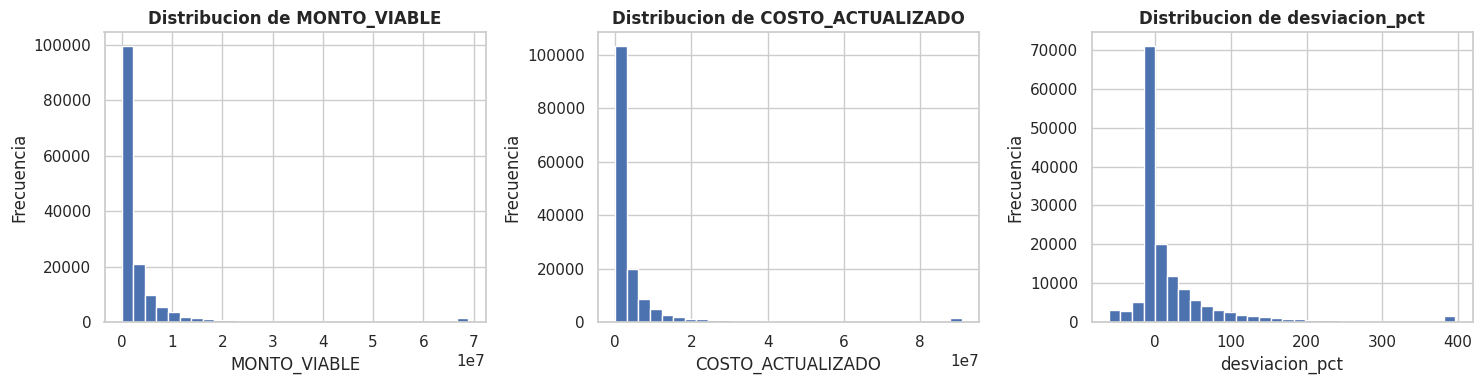

In [13]:
numeric_cols = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'desviacion_pct']

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols * 5, n_rows * 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    clip_lo = df_valido[col].quantile(0.01)
    clip_hi = df_valido[col].quantile(0.99)
    df_valido[col].clip(clip_lo, clip_hi).hist(bins=30)
    plt.title(f'Distribucion de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

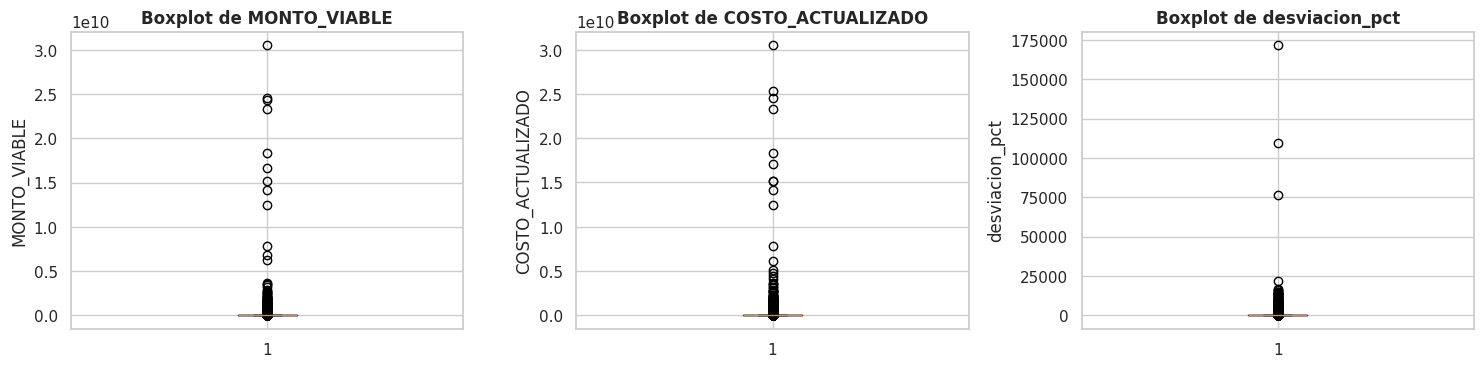

In [14]:
plt.figure(figsize=(n_cols * 5, n_rows * 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.boxplot(df_valido[col].dropna())
    plt.title(f'Boxplot de {col}')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

#### Variables categóricas

In [15]:
categorical_cols = ['NIVEL', 'SECTOR', 'FUNCION', 'DES_MODALIDAD', 'TIPO_INVERSION', 'DEPARTAMENTO']
categorical_cols = [c for c in categorical_cols if c in df_valido.columns]

for col in categorical_cols:
    print(f'\n{col}')
    print(df_valido[col].value_counts().head(10))


NIVEL
NIVEL
GL    123617
GR     13500
GN     12661
Name: count, dtype: int64

SECTOR
SECTOR
GOBIERNOS LOCALES                       123617
GOBIERNOS REGIONALES                     13500
EDUCACION                                 2335
VIVIENDA, CONSTRUCCION Y SANEAMIENTO      1939
AGRICULTURA Y RIEGO                       1409
SALUD                                     1254
TRANSPORTES Y COMUNICACIONES              1215
FONAFE                                    1117
ESSALUD                                    818
INTERIOR                                   629
Name: count, dtype: int64

FUNCION
FUNCION
TRANSPORTE                                         36073
EDUCACIÓN                                          19488
SANEAMIENTO                                        19295
CULTURA Y DEPORTE                                  13280
PLANEAMIENTO, GESTIÓN Y RESERVA DE CONTINGENCIA    13172
AGROPECUARIA                                       11274
VIVIENDA Y DESARROLLO URBANO                        

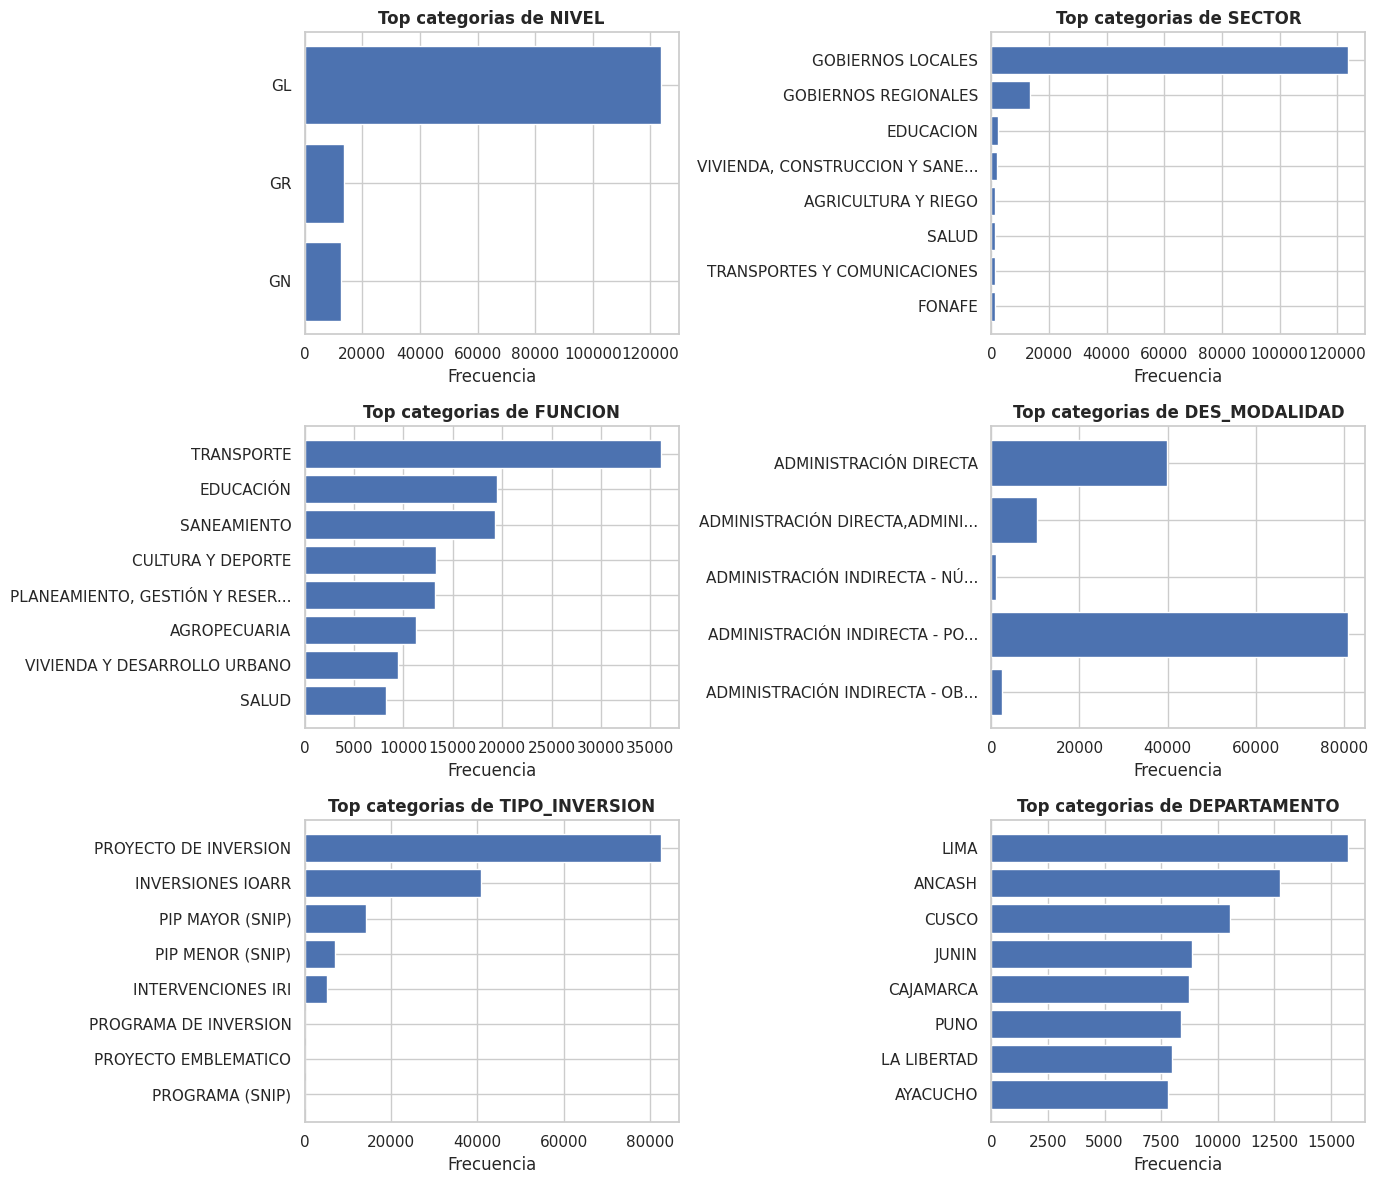

In [16]:
n_cols_cat = 2
n_rows_cat = (len(categorical_cols) + n_cols_cat - 1) // n_cols_cat

fig, axes = plt.subplots(n_rows_cat, n_cols_cat, figsize=(n_cols_cat * 7, n_rows_cat * 4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    top = df_valido[col].value_counts().head(8).sort_values()
    etiquetas = [etiqueta_corta(v) for v in top.index]
    axes[i].barh(etiquetas, top.values)
    axes[i].set_title(f'Top categorias de {col}')
    axes[i].set_xlabel('Frecuencia')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 4.3 Análisis bivariado: relación con la variable objetivo

Ahora cruzamos cada predictora con desviacion_pct: desviación mediana por categoría y matriz de correlación entre numéricas. El objetivo es identificar qué variables tienen mayor poder discriminante antes del modelado.

#### Desviación mediana por categoría

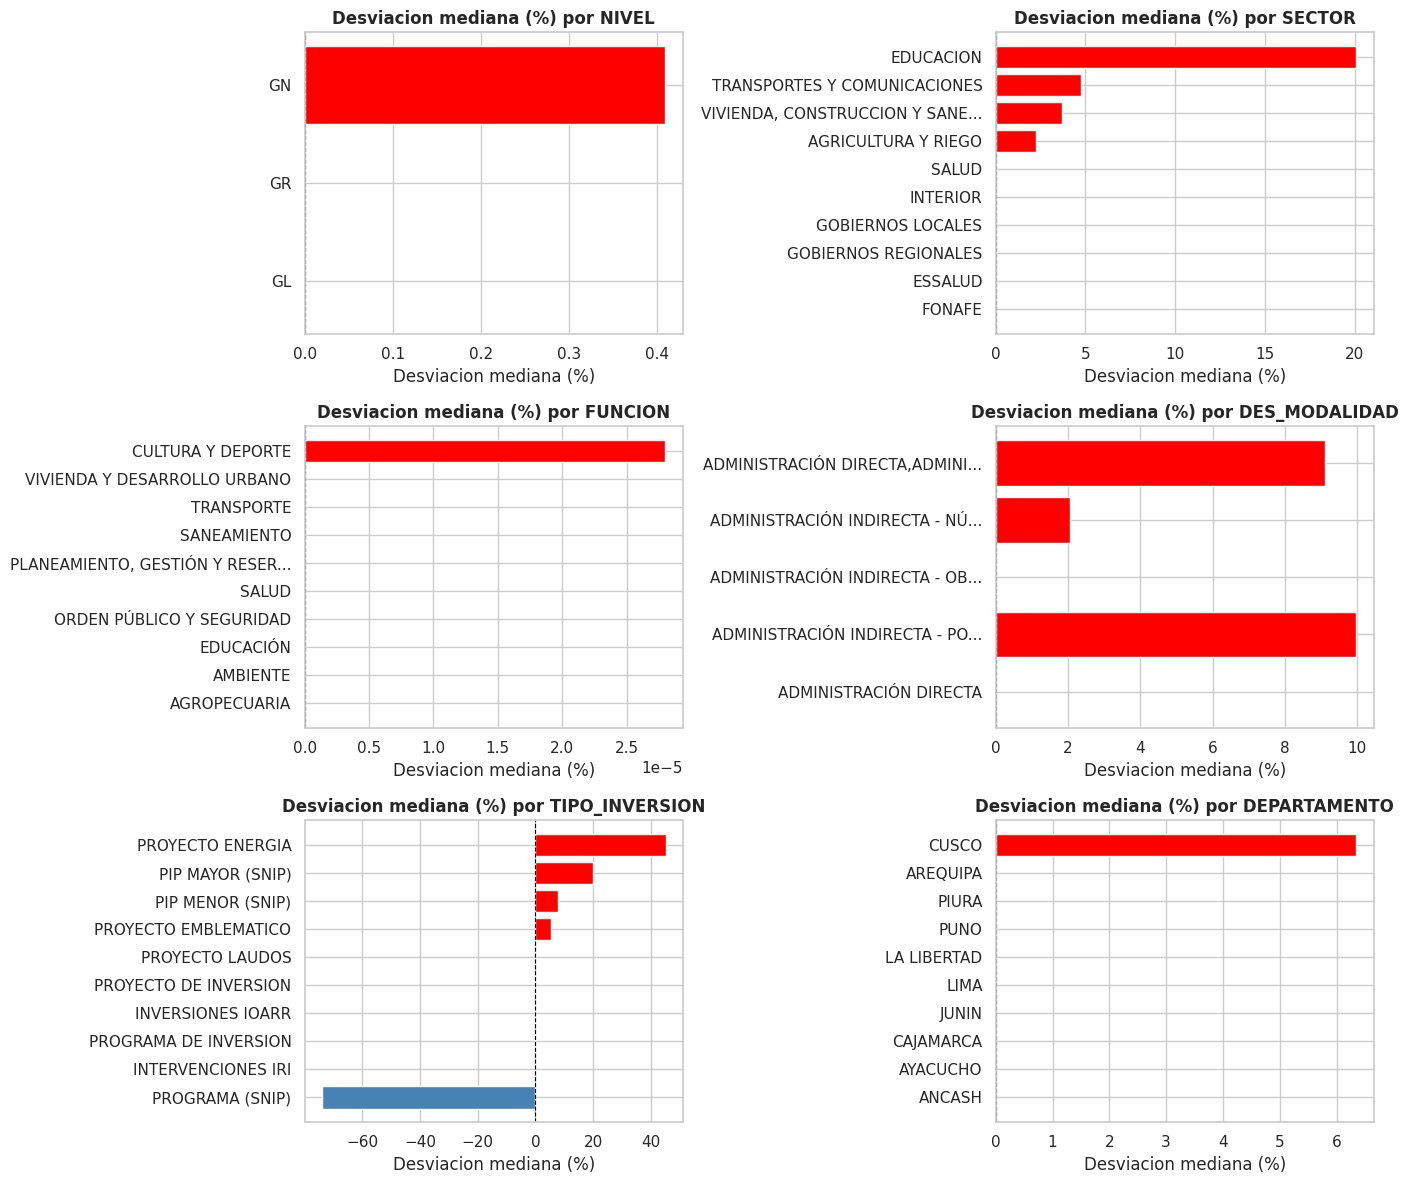

In [17]:
n_cols_biv = 2
n_rows_biv = (len(categorical_cols) + n_cols_biv - 1) // n_cols_biv

fig, axes = plt.subplots(n_rows_biv, n_cols_biv, figsize=(n_cols_biv * 7, n_rows_biv * 4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    top_cats = df_valido[col].value_counts().head(10).index
    resumen = (df_valido[df_valido[col].isin(top_cats)]
               .groupby(col)['desviacion_pct'].median().sort_values())
    etiquetas = [etiqueta_corta(v) for v in resumen.index]
    colores = ['red' if v > 0 else 'steelblue' for v in resumen.values]
    axes[i].barh(etiquetas, resumen.values, color=colores)
    axes[i].axvline(0, color='black', linewidth=0.8, linestyle='--')
    axes[i].set_title(f'Desviacion mediana (%) por {col}')
    axes[i].set_xlabel('Desviacion mediana (%)')

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Correlación entre variables numéricas

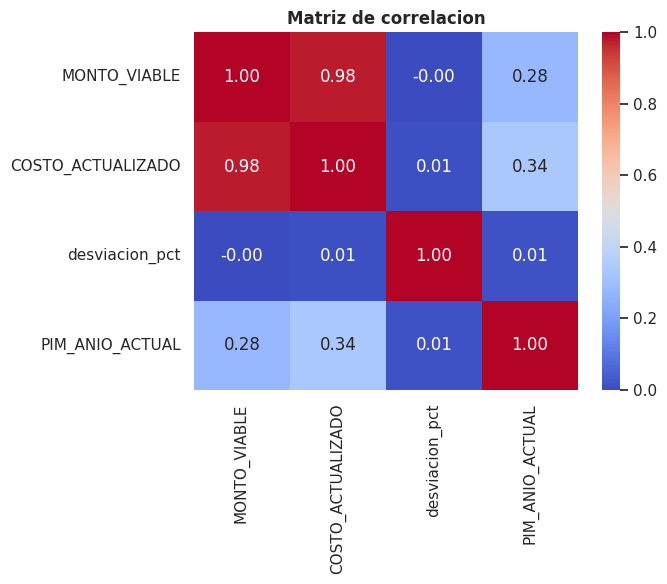

In [18]:
cols_corr = ['MONTO_VIABLE', 'COSTO_ACTUALIZADO', 'desviacion_pct', 'PIM_ANIO_ACTUAL']
cols_corr = [c for c in cols_corr if c in df_valido.columns]
corr = df_valido[cols_corr].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de correlacion')
plt.tight_layout()
plt.show()

### 4.4 Deteccion de outliers con IQR

Misma funcion vista en clase (EDA Airbnb).

In [19]:
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (series < lower) | (series > upper)

df_valido['outlier_flag'] = detect_outliers_iqr(df_valido['desviacion_pct'])
print('Outliers en desviacion_pct:', int(df_valido['outlier_flag'].sum()),
      '(', round(df_valido['outlier_flag'].mean() * 100, 1), '% )')

Outliers en desviacion_pct: 22349 ( 14.9 % )


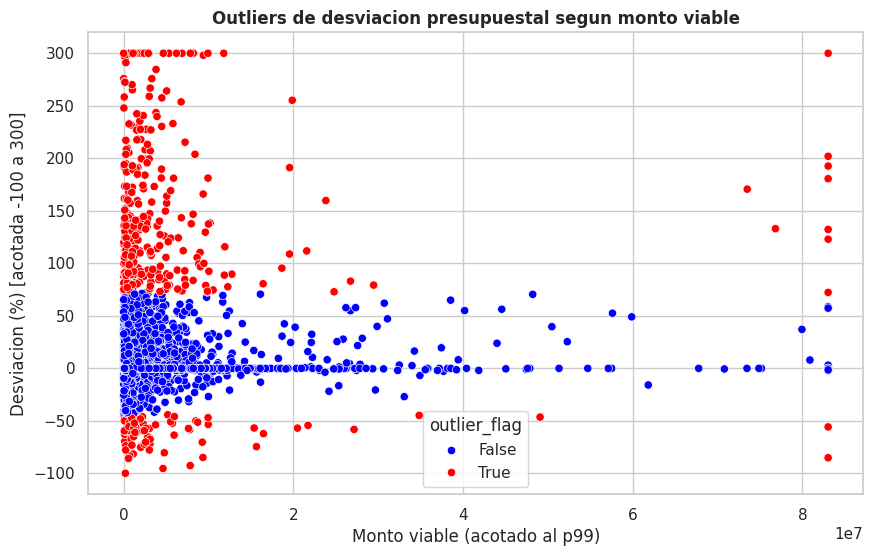

In [20]:
muestra = df_valido.sample(min(3000, len(df_valido)), random_state=3791)
plt.figure(figsize=(10, 6))
sns.scatterplot(x=muestra['MONTO_VIABLE'].clip(upper=muestra['MONTO_VIABLE'].quantile(0.99)),
                y=muestra['desviacion_pct'].clip(-100, 300),
                hue=muestra['outlier_flag'],
                palette={True: 'red', False: 'blue'})
plt.title('Outliers de desviacion presupuestal segun monto viable')
plt.xlabel('Monto viable (acotado al p99)')
plt.ylabel('Desviacion (%) [acotada -100 a 300]')
plt.show()

### 4.5 Extra: mapa de proyectos con folium

El dataset incluye LATITUD y LONGITUD. Ubicamos los 200 proyectos de mayor monto y coloreamos segun si tuvieron sobrecosto (rojo) o ahorro (azul).

In [21]:
import folium

geo = df_valido.dropna(subset=['LATITUD', 'LONGITUD'])
geo = geo[(geo['LATITUD'].between(-18.5, 0)) & (geo['LONGITUD'].between(-82, -68))]
subdata = geo.sort_values('MONTO_VIABLE', ascending=False).head(200)

mapa = folium.Map(location=[-9.19, -75.02], zoom_start=5)

for _, r in subdata.iterrows():
    color = 'red' if r['desviacion_pct'] > 0 else 'blue'
    popup_txt = str(r['NOMBRE_INVERSION'])[:45] + ' | ' + str(round(r['desviacion_pct'], 0)) + '%'
    folium.CircleMarker(location=[r['LATITUD'], r['LONGITUD']],
                        radius=4, color=color, fill=True,
                        popup=popup_txt).add_to(mapa)
mapa

### 4.6 Tendencia temporal + sesgo sin actualización


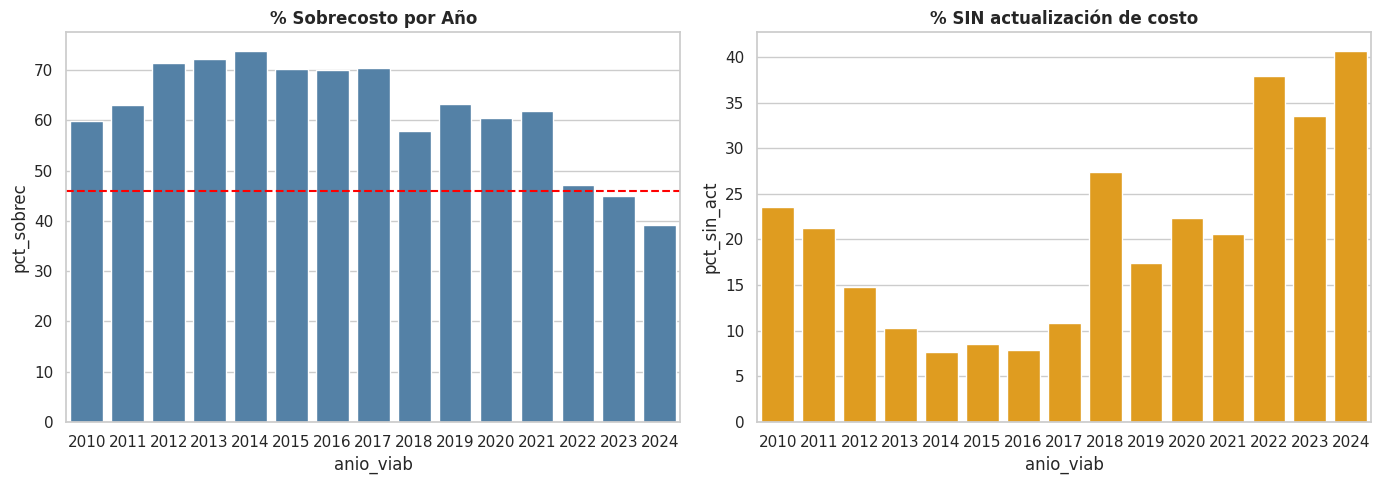

 anio_viab     n  mediana  pct_sobrec  pct_sin_act
      2010   893      9.2        59.9         23.5
      2011  1018     13.5        63.2         21.2
      2012  2077     20.2        71.4         14.8
      2013  2471     18.7        72.3         10.3
      2014  2027     23.5        73.9          7.7
      2015  3403     15.4        70.2          8.6
      2016  3906     16.5        70.0          7.9
      2017  3419     23.0        70.4         10.8
      2018  4978      7.3        58.0         27.4
      2019  9842      7.9        63.3         17.4
      2020  9899      8.4        60.4         22.4
      2021  9398      9.5        61.9         20.6
      2022 12135      0.0        47.2         37.9
      2023 21764      0.0        44.9         33.6
      2024 20640      0.0        39.2         40.7

⚠ Los años 2022-2024 muestran sesgo por falta de actualización (mediana≈0).


In [22]:
# Extraer año de viabilidad (FECHA_VIABILIDAD todavía es string en esta sección)
# 1. Variables y Agregación (Todo en un solo bloque)
df_valido['anio_viab'] = pd.to_datetime(df_valido['FECHA_VIABILIDAD'], errors='coerce').dt.year
df_valido['sin_act'] = (df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE']).abs() < 1

temporal = df_valido.query('2010 <= anio_viab <= 2024').groupby('anio_viab').agg(
    n=('desviacion_pct', 'count'),
    mediana=('desviacion_pct', 'median'),
    pct_sobrec=('desviacion_pct', lambda x: (x > 0).mean() * 100),
    pct_sin_act=('sin_act', lambda x: x.mean() * 100)
).reset_index()

# 2. Visualización (Seaborn reduce 10 líneas a 4)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=temporal, x='anio_viab', y='pct_sobrec', ax=axes[0], color='steelblue').set_title('% Sobrecosto por Año')
axes[0].axhline(46, color='red', linestyle='--', label='Promedio 46%')

sns.barplot(data=temporal, x='anio_viab', y='pct_sin_act', ax=axes[1], color='orange').set_title('% SIN actualización de costo')

plt.tight_layout(); plt.show()

# 3. Resultado original impreso
print(temporal.round(1).to_string(index=False))
print("\n⚠ Los años 2022-2024 muestran sesgo por falta de actualización (mediana≈0).")


### 4.7 Análisis profundo (costo actualizado)
##Criterio de Calidad de Datos

1.   Elemento de la lista
2.   Elemento de la lista



Proyectos con costo actualizado: 94,470 (63.1% del total)

FUNCION:
                                  n  mediana  pct_sobrec
FUNCION                                                 
ENERGIA Y RECURSOS MINERALES     85     46.2        90.6
AGRARIA                         166     42.5        89.2
SALUD Y SANEAMIENTO             402     39.9        85.3
PESCA                           107     36.1        76.6
EDUCACION Y CULTURA             397     23.5        80.6
EDUCACIÓN                     12444     22.4        76.2
COMERCIO                        580     22.2        76.0
ENERGÍA                        1991     20.9        76.0
TURISMO                         435     19.6        74.7
CULTURA Y DEPORTE              8800     18.8        75.4

DEPARTAMENTO:
                  n  mediana  pct_sobrec
DEPARTAMENTO                            
TACNA          1500     38.2        81.3
MOQUEGUA       1155     34.9        80.1
CUSCO          7313     31.4        79.5
AMAZONAS       2222     24.8

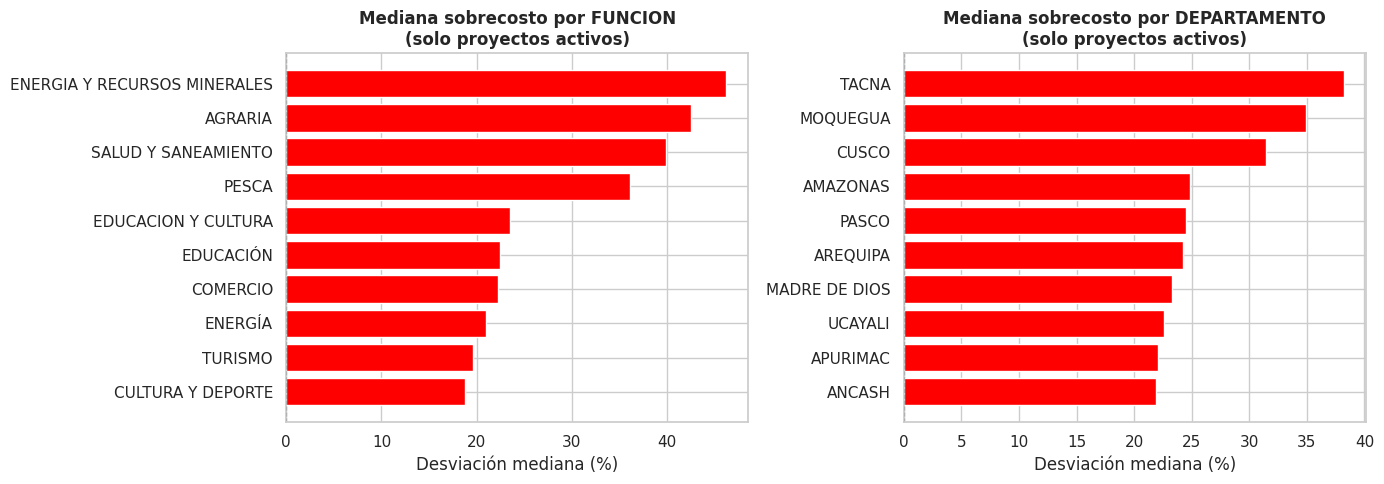

In [23]:
# 1. Filtro de data activa
df_act = df_valido[~df_valido['sin_act']].copy()
print(f"Proyectos con costo actualizado: {len(df_act):,} ({len(df_act)/len(df_valido):.1%} del total)\n")

# 2. Configuración: {Columna: Mínimo de proyectos para el filtro}
config_analisis = {'FUNCION': 50, 'DEPARTAMENTO': 100}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (col, min_n) in enumerate(config_analisis.items()):
    # Agregación y filtrado encadenado
    res = (df_act.groupby(col)['desviacion_pct']
           .agg(n='count', mediana='median', pct_sobrec=lambda x: (x>0).mean()*100)
           .query(f'n >= {min_n}')
           .sort_values('mediana', ascending=False).head(10))

    # Renderizado del gráfico
    colors = ['red' if v > 0 else 'steelblue' for v in res['mediana']]
    axes[i].barh([etiqueta_corta(v) for v in res.index], res['mediana'], color=colors)
    axes[i].axvline(0, color='black', lw=0.8, ls='--')
    axes[i].set(title=f'Mediana sobrecosto por {col}\n(solo proyectos activos)', xlabel='Desviación mediana (%)')
    axes[i].invert_yaxis() # Pone el valor más alto arriba

    # Imprimir tablas resumen
    print(f"{col}:\n{res.round(1).to_string(index=True)}\n")

plt.tight_layout()
plt.show()

### 4.8 Efecto del tamaño

In [24]:
import scipy.stats as stats

df_valido['tam_obra'] = pd.cut(
    df_valido['MONTO_VIABLE'],
    bins=[0, 5e5, 5e6, float('inf')],
    labels=['Pequeña (<S/0.5M)', 'Mediana (S/0.5–5M)', 'Grande (>S/5M)']
)

tam = (df_valido.groupby('tam_obra', observed=True)
    .agg(n=('desviacion_pct','count'),
         mediana=('desviacion_pct','median'),
         pct_sobrec=('desviacion_pct', lambda x: (x>0).mean()*100))
    .reset_index())
print(tam.round(1).to_string(index=False))

datos = df_valido[['MONTO_VIABLE','desviacion_pct']].dropna()
r, p = stats.spearmanr(np.log1p(datos['MONTO_VIABLE']), datos['desviacion_pct'])
print(f"\nSpearman log(monto) vs desviación_pct: r = {r:.3f}  (p = {p:.4f})")
print("→ Correlación prácticamente nula: el tamaño no predice el sobrecosto.")
print("  Las variables categóricas (FUNCION, DEPARTAMENTO, NIVEL) son más relevantes.")

          tam_obra     n  mediana  pct_sobrec
 Pequeña (<S/0.5M) 47092      0.0        47.4
Mediana (S/0.5–5M) 75711      0.0        45.6
    Grande (>S/5M) 26975      0.0        44.7

Spearman log(monto) vs desviación_pct: r = -0.010  (p = 0.0001)
→ Correlación prácticamente nula: el tamaño no predice el sobrecosto.
  Las variables categóricas (FUNCION, DEPARTAMENTO, NIVEL) son más relevantes.


### 4.9 Análisis de influencia de variables con pocos o ningún valor faltante

Variables sin valores faltantes (o con pocos) pero sin influencia en la variable objetivo también deben eliminarse. Aquí se evalúan todas las variables con ≤5% de faltantes que no son identificadores ni variables de fuga.

Las columnas de fecha se excluyen porque se transforman en la sección 5.2 (plazo_dias, anio_viabilidad). MONTO_VIABLE se analizó por separado en la sección 4.11.

In [25]:
import scipy.stats as stats
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

##Variables de fuga (ya excluidas del modelo):
#Hemos identificado y aislado 18 variables de 'fuga de información'. Estas variables contienen datos de la ejecución de la obra
# que no están disponibles al inicio del proyecto. Al excluirlas, aseguramos que nuestro modelo sea un verdadero sistema
#preventivo y no una obviedad estadística."
FUGA = {
    'COSTO_ACTUALIZADO','AVANCE_FISICO','AVANCE_EJECUCION','DEV_ANIO_ACTUAL',
    'SALDO_EJECUTAR','DEVEN_ACUMUL_ANIO_ANT','ULTIMO_DEVENGADO','PRIMER_DEVENGADO',
    'CERTIF_ANIO_ACTUAL','COMPROM_ANUAL_ANIO_ACTUAL','SITUACION','ESTADO',
    'ETAPA_F8','ETAPA_F9','FEC_REG_F9','FEC_FIN_EJEC_FISICA','FEC_INI_EJEC_FISICA',
    'ULT_FEC_DECLA_ESTIM'
}

In [26]:
# Identificadores y descriptivos (sin valor predictivo por definición):
#Separamos códigos únicos, nombres y ubicaciones específicas que solo sirven para etiquetar cada proyecto de forma individual.
#Estas columnas se eliminan porque su alta variedad impide que el modelo generalice patrones aplicables a obras nuevas.
#Su exclusión evita que el algoritmo memorice casos particulares (overfitting) en lugar de aprender tendencias estadísticas reales.
IDENTIFICADORES = {
    'CODIGO_UNICO','NOMBRE_INVERSION','UBIGEO','SEC_EJEC','CODIGO_SNIP',
    'NOMBRE_UEI','NOMBRE_OPMI','NOMBRE_UEP','NOMBRE_UF','ENTIDAD'
}

# Columnas derivadas creadas en este notebook (no son variables originales)
#Agrupamos la variable objetivo ( Y Y ) y los cálculos propios realizados durante la exploración y limpieza de la base de datos.
#Se aíslan para que el análisis de importancia se realice exclusivamente sobre los datos originales y puros del MEF. Esto permite
#evaluar con total objetividad cómo influyen los factores iniciales del proyecto sobre el porcentaje de sobrecosto.
DERIVADAS = {
    'desviacion_pct','desviacion_pct_cap','outlier_flag',
    'anio_viab','sin_actualizar','tam_obra'
}


In [27]:

# MONTO_VIABLE ya se analizó en 4.11; las fechas se transforman en 5.2
YA_CUBIERTAS = {'MONTO_VIABLE'}

# ── 1. Variables candidatas: ≤5% faltantes ──────────────────
#Calculamos el porcentaje de valores nulos por columna para conservar únicamente aquellas con alta integridad de información (umbral menor al 5%),
# filtrando el dataset al excluir sistemáticamente las variables marcadas como fugas, identificadores únicos y columnas derivadas. De esta manera,
# obtenemos el listado definitivo de "Variables Candidatas" que están estadísticamente aptas para ser evaluadas mediante las pruebas de importancia y
#correlación necesarias para el modelo predictivo.
miss_pct = df.isnull().mean() * 100
candidatas = miss_pct[
    (miss_pct <= 5) &
    (~miss_pct.index.isin(FUGA)) &
    (~miss_pct.index.isin(IDENTIFICADORES)) &
    (~miss_pct.index.isin(DERIVADAS)) &
    (~miss_pct.index.isin(YA_CUBIERTAS))
].sort_values()

print(f"Variables a analizar (≤5% faltantes): {len(candidatas)}\n")


Variables a analizar (≤5% faltantes): 28



In [28]:


# ── 2. Clasificar por tipo ──────────────────────────────────
#Este bloque de código actúa como un filtro inteligente que clasifica las variables del proyecto en dos categorías: numéricas y categóricas.
# Mediante una prueba de conversión, el algoritmo identifica qué columnas contienen principalmente datos cuantitativos y cuáles contienen etiquetas o texto,
# permitiendo organizar el flujo de trabajo para aplicar el análisis estadístico correcto a cada tipo de dato en las etapas siguientes.
numericas, categoricas = [], []
for col in candidatas.index:
    if pd.to_numeric(df[col], errors='coerce').notna().mean() > 0.3:
        numericas.append(col)
    else:
        categoricas.append(col)

# ── 3. Numéricas: Spearman con desviacion_pct ───────────────
#Evaluamos la relación entre cada variable numérica y el porcentaje de sobrecosto mediante el coeficiente de correlación de Spearman,
#una métrica estadística que mide la fuerza de asociación entre dos variables. El proceso filtra columnas con muestras insuficientes (menos de 200 registros)
# y calcula el impacto real de cada predictor sobre la desviación presupuestal; finalmente, se aplica un criterio técnico para conservar únicamente las variables
#con un efecto significativo (correlación ≥ 0.05  ), eliminando aquellas que no poseen valor predictivo para el modelo.
resultados = []
for col in numericas:
    datos = df_valido[[col, 'desviacion_pct']].copy()
    datos[col] = pd.to_numeric(datos[col], errors='coerce')
    datos = datos.dropna()
    if len(datos) < 200: continue
    r, _ = stats.spearmanr(datos[col], datos['desviacion_pct'])
    resultados.append({
        'Variable': col, 'Tipo': 'Numérica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'Spearman |r|',
        'Efecto': round(abs(r), 4),
        'Decisión': 'MANTENER' if abs(r) >= 0.05 else 'ELIMINAR'
    })

In [29]:
# ── 4. Categóricas: Kruskal-Wallis + eta² ──────────────────
#Este bloque evalúa el impacto de las variables categóricas sobre el sobrecosto mediante el test no paramétrico de Kruskal-Wallis,
# el cual determina si existen diferencias estadísticamente significativas entre los distintos grupos de una categoría (ej. diferentes sectores o regiones).
# Para cuantificar la magnitud de esta influencia, calculamos el efecto de tamaño mediante la métrica Eta cuadrado ( η 2 η 2 ), lo que permite identificar qué
# variables explican mejor la varianza del sobrecosto; finalmente, aplicamos un criterio de selección para conservar únicamente los predictores con significancia
# estadística ( p<0.05 ) y un tamaño de efecto relevante ( η 2 ≥ 0.001 ), descartando el ruido y las columnas de fechas detectadas automáticamente.
fechas_detectadas = []
for col in categoricas:
    # Detectar si es una fecha disfrazada de categórica
    if pd.to_datetime(df[col], errors='coerce').notna().mean() > 0.5:
        fechas_detectadas.append(col)
        continue
    datos = df_valido[[col, 'desviacion_pct']].dropna()
    if len(datos) < 200 or datos[col].nunique() < 2: continue
    grupos = [g['desviacion_pct'].values for _, g in datos.groupby(col) if len(g) >= 30]
    if len(grupos) < 2: continue
    stat, p = stats.kruskal(*grupos)
    n, k = len(datos), len(grupos)
    eta2 = round(max(0.0, (stat - k + 1) / (n - k)), 4)
    resultados.append({
        'Variable': col, 'Tipo': 'Categórica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'eta²',
        'Efecto': eta2,
        'Decisión': 'MANTENER' if (p < 0.05 and eta2 >= 0.001) else 'ELIMINAR'
    })

if fechas_detectadas:
    print(f"Fechas detectadas (se transforman en 5.2, no se evalúan aquí): {fechas_detectadas}\n")

df_res = pd.DataFrame(resultados).sort_values('Efecto', ascending=False)

Fechas detectadas (se transforman en 5.2, no se evalúan aquí): ['FECHA_REGISTRO', 'FECHA_VIABILIDAD']



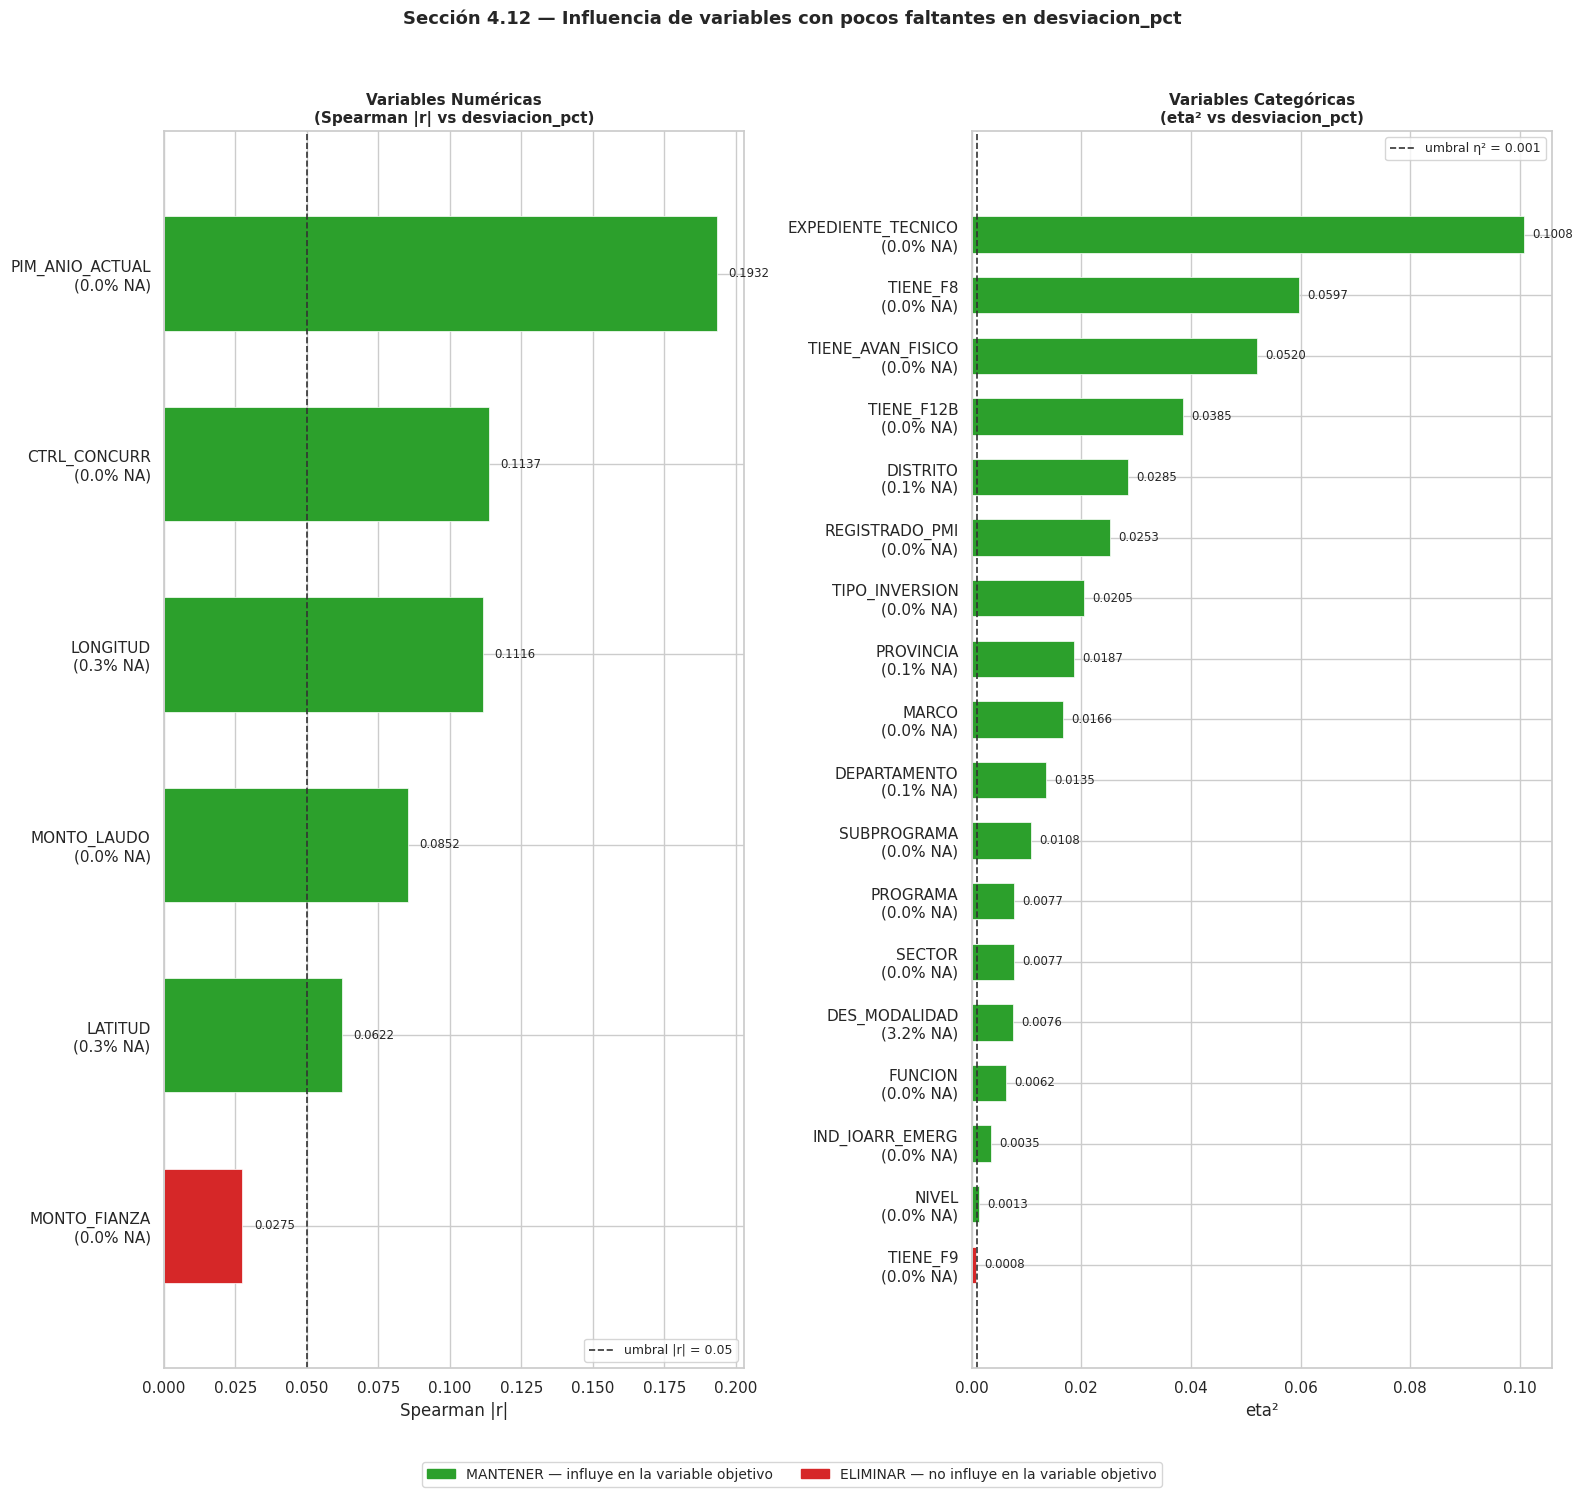

In [30]:



# ── 5. Gráfico de barras (2 paneles) ────────────────────────
VERDE, ROJO = '#2ca02c', '#d62728'
col_map = {'MANTENER': VERDE, 'ELIMINAR': ROJO}

tipos  = [('Numérica',   'Spearman |r|', 0.05,  'umbral |r| = 0.05'),
          ('Categórica', 'eta²',         0.001, 'umbral η² = 0.001')]
n_rows = max(4, len(df_res) // 2 + 2)
fig, axes = plt.subplots(1, 2, figsize=(16, n_rows))

for ax, (tipo, metrica_label, umbral, umbral_label) in zip(axes, tipos):
    sub = df_res[df_res['Tipo'] == tipo].sort_values('Efecto')
    if sub.empty:
        ax.text(0.5, 0.5, f'Sin variables {tipo}s\nen este grupo',
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.axis('off')
        continue
    etiquetas = sub['Variable'] + '\n(' + sub['Missing %'].astype(str) + '% NA)'
    colores   = sub['Decisión'].map(col_map)
    bars      = ax.barh(etiquetas, sub['Efecto'], color=colores,
                        edgecolor='white', linewidth=0.5, height=0.6)
    ax.axvline(umbral, color='#333', linestyle='--', linewidth=1.2, label=umbral_label)
    for bar, val in zip(bars, sub['Efecto']):
        offset = max(sub['Efecto'].max() * 0.015, umbral * 0.08)
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8.5)
    ax.set_title(f'Variables {tipo}s\n({metrica_label} vs desviacion_pct)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel(metrica_label)
    ax.legend(fontsize=9)
    ax.margins(y=0.08)

leyenda = [Patch(color=VERDE, label='MANTENER — influye en la variable objetivo'),
           Patch(color=ROJO,  label='ELIMINAR — no influye en la variable objetivo')]
fig.legend(handles=leyenda, loc='lower center', ncol=2, fontsize=10,
           bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Sección 4.12 — Influencia de variables con pocos faltantes en desviacion_pct',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()



In [31]:
# ── 6. Tabla estilizada ─────────────────────────────────────
def _color_fila(row):
    bg = '#d5f5e3' if row['Decisión'] == 'MANTENER' else '#fadbd8'
    return [f'background-color: {bg}'] * len(row)

display(df_res.style
    .apply(_color_fila, axis=1)
    .format({'Missing %': '{:.1f}%', 'Efecto': '{:.4f}'})
    .set_caption('Tabla 4.12 — Variables con pocos faltantes: ¿mantener o eliminar?')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size','13px'), ('font-weight','bold'), ('margin-bottom','8px')]},
        {'selector': 'th',
         'props': [('background-color','#2c3e50'), ('color','white'), ('font-size','11px')]}
    ])
    .hide(axis='index'))



Variable,Tipo,Missing %,Métrica,Efecto,Decisión
PIM_ANIO_ACTUAL,Numérica,0.0%,Spearman |r|,0.1932,MANTENER
CTRL_CONCURR,Numérica,0.0%,Spearman |r|,0.1137,MANTENER
LONGITUD,Numérica,0.3%,Spearman |r|,0.1116,MANTENER
EXPEDIENTE_TECNICO,Categórica,0.0%,eta²,0.1008,MANTENER
MONTO_LAUDO,Numérica,0.0%,Spearman |r|,0.0852,MANTENER
LATITUD,Numérica,0.3%,Spearman |r|,0.0622,MANTENER
TIENE_F8,Categórica,0.0%,eta²,0.0597,MANTENER
TIENE_AVAN_FISICO,Categórica,0.0%,eta²,0.0520,MANTENER
TIENE_F12B,Categórica,0.0%,eta²,0.0385,MANTENER
DISTRITO,Categórica,0.1%,eta²,0.0285,MANTENER


In [32]:
# ── 7. Resumen final ────────────────────────────────────────
mantener = df_res[df_res['Decisión'] == 'MANTENER']['Variable'].tolist()
eliminar = df_res[df_res['Decisión'] == 'ELIMINAR']['Variable'].tolist()
print(f"\nMANTENER ({len(mantener)} vars): {mantener}")
print(f"ELIMINAR ({len(eliminar)} vars): {eliminar}")
print("\nNota: MONTO_VIABLE se analizó en 4.11 (Spearman r ≈ -0.01, sin efecto")
print("monotónico). Se mantiene porque se usa para crear monto_viable_log en 5.2")
print("y puede tener efectos no lineales que capturan Random Forest y Gradient Boosting.")


MANTENER (22 vars): ['PIM_ANIO_ACTUAL', 'CTRL_CONCURR', 'LONGITUD', 'EXPEDIENTE_TECNICO', 'MONTO_LAUDO', 'LATITUD', 'TIENE_F8', 'TIENE_AVAN_FISICO', 'TIENE_F12B', 'DISTRITO', 'REGISTRADO_PMI', 'TIPO_INVERSION', 'PROVINCIA', 'MARCO', 'DEPARTAMENTO', 'SUBPROGRAMA', 'SECTOR', 'PROGRAMA', 'DES_MODALIDAD', 'FUNCION', 'IND_IOARR_EMERG', 'NIVEL']
ELIMINAR (3 vars): ['MONTO_FIANZA', 'TIENE_F9', 'ANIO_PROCESO']

Nota: MONTO_VIABLE se analizó en 4.11 (Spearman r ≈ -0.01, sin efecto
monotónico). Se mantiene porque se usa para crear monto_viable_log en 5.2
y puede tener efectos no lineales que capturan Random Forest y Gradient Boosting.


### 4.10 Muchos faltantes: imputar/eliminar
Las variables con muchos NAs se clasifican en dos grupos:
- **Sin influencia en desviacion_pct** → se eliminan del pipeline
- **Con influencia en desviacion_pct** → se imputan (mediana para numéricas, moda para categóricas)

El análisis se separa por tipo de variable porque los tests estadísticos difieren.

In [33]:
import scipy.stats as stats
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')
#solo estamos definiendo que hacer cuando se presente con uno de esos "enfermos" detectados por el inspector.
# Variables de fuga (excluir del análisis)
#Este bloque establece los criterios técnicos y de negocio para el tratamiento de variables con alta proporción de datos faltantes, diferenciando entre la eliminación de
#predictores irrelevantes y la imputación de aquellos con valor predictivo. Mediante una función lógica personalizada, el algoritmo determina el método de limpieza más adecuado
#según la naturaleza del dato: asigna valores constantes de cero a variables presupuestales (PMI/PIA/PIM) basándose en el contexto del sistema Invierte.pe, utiliza la moda para
# etiquetas categóricas y la mediana para variables numéricas y fechas. Este enfoque garantiza que la reconstrucción de la información faltante sea estadísticamente robusta y
#coherente con la realidad operativa de los proyectos de inversión pública.
FUGA = {
    'COSTO_ACTUALIZADO','AVANCE_FISICO','AVANCE_EJECUCION','DEV_ANIO_ACTUAL',
    'SALDO_EJECUTAR','DEVEN_ACUMUL_ANIO_ANT','ULTIMO_DEVENGADO','PRIMER_DEVENGADO',
    'CERTIF_ANIO_ACTUAL','COMPROM_ANUAL_ANIO_ACTUAL','SITUACION','ESTADO',
    'ETAPA_F8','ETAPA_F9','FEC_REG_F9','FEC_FIN_EJEC_FISICA','FEC_INI_EJEC_FISICA',
    'ULT_FEC_DECLA_ESTIM'
}

def elegir_metodo_imputacion(variable, tipo, decision):
    # Solo tiene sentido un metodo si la variable se va a IMPUTAR
    if decision == 'ELIMINAR':
        return '— (se elimina)'
    var_upper = variable.upper()
    if tipo == 'Categórica':
        # Algunas columnas de fecha quedan mal clasificadas como categoricas
        # (pd.to_numeric falla en fechas); las detectamos aqui.
        es_fecha = pd.to_datetime(df[variable], errors='coerce').notna().mean() > 0.5
        return 'Mediana (fecha)' if es_fecha else 'Moda (mas frecuente)'
    else:
        # PMI/PIA/PIM: el NaN suele significar "no incluido en ese ciclo
        # presupuestal", no un valor desconocido -> 0 es mas correcto que la mediana
        if any(p in var_upper for p in ['PMI_ANIO', 'PIA_ANIO', 'PIM_ANIO']):
            return 'Constante = 0'
        return 'Mediana'

In [34]:
# ── 1. Variables candidatas (>5% faltantes, sin fuga) ─────────
#Este bloque de código filtra el conjunto de datos para identificar variables que presentan una proporción de datos faltantes superior al 5%, excluyendo
#simultáneamente aquellas identificadas previamente como variables de fuga. El objetivo es aislar los predictores que requieren un tratamiento especial de
#limpieza o imputación debido a su nivel de incompletitud, ordenándolos de mayor a menor impacto de nulidad para priorizar el análisis de su relevancia estadística frente al sobrecosto presupuestal.
miss_pct  = df.isnull().mean() * 100
candidatas = miss_pct[(miss_pct > 5) & (~miss_pct.index.isin(FUGA))].sort_values(ascending=False)

In [35]:

# ── 2. Clasificar por tipo ────────────────────────────────────
#Este bloque realiza una clasificación técnica de las variables que presentan más de un 5% de datos faltantes, dividiéndolas en grupos numéricos y categóricos. Mediante
#un test de conversión de datos, el algoritmo identifica la naturaleza de cada predictor para determinar la estrategia de imputación más adecuada; esto asegura que, en el
# siguiente paso, se aplique correctamente la mediana para reconstruir valores cuantitativos y la moda para etiquetas de texto, preservando así la coherencia estadística del dataset de inversiones antes de entrar al modelo.
numericas_miss, categoricas_miss = [], []
for col in candidatas.index:
    if pd.to_numeric(df[col], errors='coerce').notna().mean() > 0.3:
        numericas_miss.append(col)
    else:
        categoricas_miss.append(col)

In [36]:
# ── 3. Numéricas: Spearman con desviacion_pct ─────────────────
#Este bloque de código ejecuta un análisis de correlación de Spearman sobre las variables numéricas que presentan más del 5% de datos faltantes para determinar su utilidad predictiva.
#El algoritmo evalúa la fuerza de asociación de cada predictor con el sobrecosto presupuestal; si la variable supera el umbral de significancia ( ∣ r ∣ ≥ 0.05 ), se marca para ser
# "imputada" (reparada) mediante la lógica de negocio previamente definida, de lo contrario, se elimina del dataset. Este proceso de triaje asegura que solo se apliquen técnicas de
#reconstrucción de datos sobre variables que aportan valor real al modelo, evitando la introducción de ruido estadístico innecesario.
resultados = []
for col in numericas_miss:
    datos = df_valido[[col, 'desviacion_pct']].copy()
    datos[col] = pd.to_numeric(datos[col], errors='coerce')
    datos = datos.dropna()
    if len(datos) < 200: continue
    r, _ = stats.spearmanr(datos[col], datos['desviacion_pct'])
    decision = 'IMPUTAR' if abs(r) >= 0.05 else 'ELIMINAR'
    resultados.append({
        'Variable': col, 'Tipo': 'Numérica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'Spearman |r|',
        'Efecto': round(abs(r), 4),
        'Decisión': decision,
        'Método imputación': elegir_metodo_imputacion(col, 'Numérica', decision)
    })

In [37]:

# ── 4. Categóricas: Kruskal-Wallis + eta² ────────────────────
#En este bloque, se realiza un análisis de importancia sobre las variables categóricas que presentan más del 5% de datos faltantes, utilizando el test
#de Kruskal-Wallis y la métrica de efecto Eta cuadrado ( η 2 ). El objetivo es determinar si una variable, a pesar de estar incompleta, posee un impacto estadísticamente
# significativo y material sobre el sobrecosto presupuestal; aquellas que superan los umbrales de significancia ( p < 0.05 ) y de tamaño de efecto ( η 2 ≥ 0.001  )
 #son marcadas para ser reconstruidas mediante técnicas de imputación, mientras que las variables irrelevantes son eliminadas. Este procedimiento asegura una selección rigurosa de
 #predictores, optimizando la calidad de la información que alimentará el modelo final de Machine Learning.
for col in categoricas_miss:
    datos = df_valido[[col, 'desviacion_pct']].dropna()
    if len(datos) < 200 or datos[col].nunique() < 2: continue
    grupos = [g['desviacion_pct'].values for _, g in datos.groupby(col) if len(g) >= 30]
    if len(grupos) < 2: continue
    stat, p = stats.kruskal(*grupos)
    n, k  = len(datos), len(grupos)
    eta2  = round(max(0.0, (stat - k + 1) / (n - k)), 4)
    decision = 'IMPUTAR' if (p < 0.05 and eta2 >= 0.001) else 'ELIMINAR'
    resultados.append({
        'Variable': col, 'Tipo': 'Categórica',
        'Missing %': round(miss_pct[col], 1),
        'Métrica': 'eta²',
        'Efecto': eta2,
        'Decisión': decision,
        'Método imputación': elegir_metodo_imputacion(col, 'Categórica', decision)
    })

df_res = pd.DataFrame(resultados).sort_values('Missing %', ascending=False)

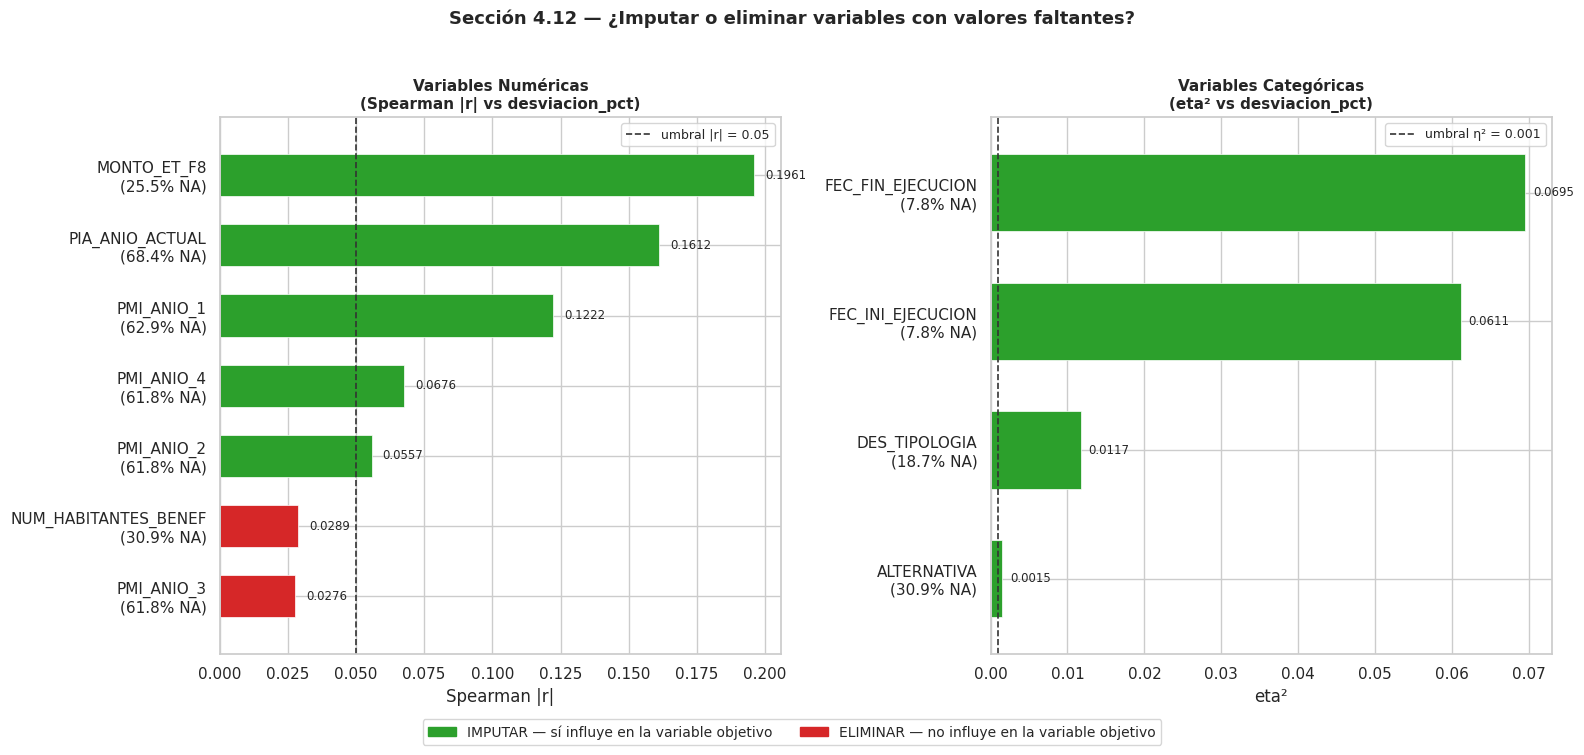

In [38]:


# ── 5. Gráfico de barras (2 paneles) ─────────────────────────
VERDE, ROJO = '#2ca02c', '#d62728'
col_map = {'IMPUTAR': VERDE, 'ELIMINAR': ROJO}

tipos   = [('Numérica',   'Spearman |r|', 0.05,  'umbral |r| = 0.05'),
           ('Categórica', 'eta²',         0.001, 'umbral η² = 0.001')]
n_rows  = max(4, len(df_res) // 2 + 2)
fig, axes = plt.subplots(1, 2, figsize=(16, n_rows))

for ax, (tipo, metrica_label, umbral, umbral_label) in zip(axes, tipos):
    sub = df_res[df_res['Tipo'] == tipo].sort_values('Efecto')
    if sub.empty:
        ax.text(0.5, 0.5, f'Sin variables {tipo}s\ncon >5% faltantes',
                ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.axis('off')
        continue

    etiquetas = sub['Variable'] + '\n(' + sub['Missing %'].astype(str) + '% NA)'
    colores   = sub['Decisión'].map(col_map)
    bars      = ax.barh(etiquetas, sub['Efecto'], color=colores,
                        edgecolor='white', linewidth=0.5, height=0.6)
    ax.axvline(umbral, color='#333', linestyle='--', linewidth=1.2, label=umbral_label)

    for bar, val in zip(bars, sub['Efecto']):
        offset = max(sub['Efecto'].max() * 0.015, umbral * 0.08)
        ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=8.5)

    ax.set_title(f'Variables {tipo}s\n({metrica_label} vs desviacion_pct)',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel(metrica_label)
    ax.legend(fontsize=9)
    ax.margins(y=0.08)

leyenda_items = [Patch(color=VERDE, label='IMPUTAR — sí influye en la variable objetivo'),
                 Patch(color=ROJO,  label='ELIMINAR — no influye en la variable objetivo')]
fig.legend(handles=leyenda_items, loc='lower center', ncol=2,
           fontsize=10, bbox_to_anchor=(0.5, -0.04))
plt.suptitle('Sección 4.12 — ¿Imputar o eliminar variables con valores faltantes?',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [39]:
# ── 6. Tabla estilizada ───────────────────────────────────────
def _color_fila(row):
    bg = '#d5f5e3' if row['Decisión'] == 'IMPUTAR' else '#fadbd8'
    return [f'background-color: {bg}'] * len(row)

def _color_miss(val):
    if val > 60:   return 'color: #c0392b; font-weight: bold'
    elif val > 30: return 'color: #e67e22; font-weight: bold'
    return 'color: #27ae60'

display(df_res.style
    .apply(_color_fila, axis=1)
    .map(_color_miss, subset=['Missing %'])
    .format({'Missing %': '{:.1f}%', 'Efecto': '{:.4f}'})
    .set_caption('Tabla 4.12 — Decisión: imputar o eliminar variables con valores faltantes')
    .set_table_styles([
        {'selector': 'caption',
         'props': [('font-size','13px'), ('font-weight','bold'), ('margin-bottom','8px')]},
        {'selector': 'th',
         'props': [('background-color','#2c3e50'), ('color','white'), ('font-size','11px')]}
    ])
    .hide(axis='index'))

# ── 7. Resumen final ──────────────────────────────────────────
imputar  = df_res[df_res['Decisión'] == 'IMPUTAR']['Variable'].tolist()
eliminar = df_res[df_res['Decisión'] == 'ELIMINAR']['Variable'].tolist()
print(f"\nIMPUTAR  ({len(imputar)} vars): {imputar}")
print(f"ELIMINAR ({len(eliminar)} vars): {eliminar}")

Variable,Tipo,Missing %,Métrica,Efecto,Decisión,Método imputación
PIA_ANIO_ACTUAL,Numérica,68.4%,Spearman |r|,0.1612,IMPUTAR,Constante = 0
PMI_ANIO_1,Numérica,62.9%,Spearman |r|,0.1222,IMPUTAR,Constante = 0
PMI_ANIO_4,Numérica,61.8%,Spearman |r|,0.0676,IMPUTAR,Constante = 0
PMI_ANIO_2,Numérica,61.8%,Spearman |r|,0.0557,IMPUTAR,Constante = 0
PMI_ANIO_3,Numérica,61.8%,Spearman |r|,0.0276,ELIMINAR,— (se elimina)
NUM_HABITANTES_BENEF,Numérica,30.9%,Spearman |r|,0.0289,ELIMINAR,— (se elimina)
ALTERNATIVA,Categórica,30.9%,eta²,0.0015,IMPUTAR,Moda (mas frecuente)
MONTO_ET_F8,Numérica,25.5%,Spearman |r|,0.1961,IMPUTAR,Mediana
DES_TIPOLOGIA,Categórica,18.7%,eta²,0.0117,IMPUTAR,Moda (mas frecuente)
FEC_INI_EJECUCION,Categórica,7.8%,eta²,0.0611,IMPUTAR,Mediana (fecha)



IMPUTAR  (9 vars): ['PIA_ANIO_ACTUAL', 'PMI_ANIO_1', 'PMI_ANIO_4', 'PMI_ANIO_2', 'ALTERNATIVA', 'MONTO_ET_F8', 'DES_TIPOLOGIA', 'FEC_INI_EJECUCION', 'FEC_FIN_EJECUCION']
ELIMINAR (2 vars): ['PMI_ANIO_3', 'NUM_HABITANTES_BENEF']


### 4.11 Resumen consolidado de hallazgos (Insights)

Síntesis de todo el análisis exploratorio, siguiendo el flujo de las secciones 4.1 a 4.12:

**A. Variable objetivo y datos (4.1–4.3)**

1. **Volumen y completitud:** 150,020 registros × 68 columnas; 149,778 proyectos válidos (MONTO_VIABLE > 0 y COSTO_ACTUALIZADO disponible). Las predictoras seleccionadas tienen menos de 0.5% de faltantes.

2. **Distribución de la variable objetivo:** desviacion_pct presenta asimetría extrema (skewness = 189.57): media 38.85% vs. mediana 0.00%. El 46.0% de los proyectos válidos tiene sobrecosto positivo; el rango va de -100% a 171,833%.

**B. Relaciones con la variable objetivo (4.4–4.7)**

3. **Poder discriminante de las categóricas:** el análisis bivariado muestra diferencias claras en la desviación mediana entre categorías de FUNCION, NIVEL y DES_MODALIDAD, confirmando su valor predictivo.

4. **Correlación:** la alta correlación MONTO_VIABLE–COSTO_ACTUALIZADO confirma que modelar la desviación porcentual es más informativo que modelar el costo final directamente.

5. **Outliers (método IQR):** Q1 = 0.00, Q3 = 28.68 → límites de Winsorización [-43.01%, 71.69%]; el 14.9% de los registros son outliers. Se aplica capping y no eliminación, para conservar los sobrecostos extremos reales que el modelo debe anticipar.

6. **Geografía:** el mapa de los 200 proyectos de mayor monto muestra dispersión nacional, con sobrecostos (rojo) y ahorros (azul) presentes en todas las regiones — el riesgo no es exclusivo de una zona.

**C. Análisis profundos (4.8–4.10)**

7. **Sesgo temporal:** la mediana de sobrecosto fue alta en 2014–2017 (15–23%; hasta 74% de proyectos con sobrecosto) y cae a 0% desde 2022 — pero el 34–41% de los proyectos 2022–2024 aún no tienen su costo actualizado (COSTO_ACTUALIZADO = MONTO_VIABLE), por lo que su desviación es artificialmente cero y son poco informativos para entrenar.

8. **Sobrecosto por función y región (solo proyectos con costo actualizado):** ENERGÍA Y RECURSOS MINERALES (mediana 46.2%; 90.6% con sobrecosto), AGRARIA (42.5%; 89.2%) y EDUCACIÓN (22.4%; 76.2%) concentran el mayor riesgo. Por región destacan TACNA (9.3%) y CUSCO (6.3%).

9. **El tamaño no predice el sobrecosto:** Spearman log(MONTO_VIABLE) vs. desviacion_pct: r = -0.01. Proyectos pequeños, medianos y grandes tienen tasas de sobrecosto casi idénticas (~45–47%).

**D. Selección de variables (4.11–4.12)**

10. **Variables con pocos faltantes (≤5% NA):** de las evaluadas, 22 se mantienen por su influencia (destacan PIM_ANIO_ACTUAL, CTRL_CONCURR, LONGITUD, EXPEDIENTE_TECNICO y MONTO_LAUDO); se eliminan ANIO_PROCESO, MONTO_FIANZA y TIENE_F9 por efecto prácticamente nulo, e INFORME_CIERRE se descarta por tener un solo valor. Las fechas (FECHA_VIABILIDAD, FECHA_REGISTRO) no se evalúan aquí porque se transforman en la sección 5.2.

11. **Variables con muchos faltantes (>5% NA):** 9 se imputan por tener influencia — PIA_ANIO_ACTUAL, PMI_ANIO_1/2/4 y MONTO_ET_F8 (numéricas), ALTERNATIVA y DES_TIPOLOGIA (categóricas), FEC_INI/FIN_EJECUCION (fechas) — y 2 se eliminan (PMI_ANIO_3, NUM_HABITANTES_BENEF). Métodos: constante = 0 para montos de programación presupuestal (PIA/PMI, donde el faltante significa "no programado"), mediana para MONTO_ET_F8, moda para categóricas y mediana de fecha para las fechas.

12. **Cobertura total:** las 68 variables quedan contabilizadas — 28 + 11 evaluadas por influencia, 18 de fuga excluidas a priori (solo se conocen durante/después de la obra; pasarlas por el test de influencia las mostraría artificialmente "perfectas"), 10 identificadores sin valor predictivo y MONTO_VIABLE (analizada en 4.10).


**Balance final:** de las 68 variables originales, **34 sobreviven los filtros y quedan disponibles para el modelado** — 22 con pocos faltantes que se mantienen directamente, 9 con muchos faltantes que se imputan, 2 fechas que alimentan el feature engineering de la sección 5.2 (plazo_dias, anio_viabilidad) y MONTO_VIABLE (transformada a monto_viable_log). Las otras **34 se eliminan**: 18 por fuga de información, 10 por ser identificadores, 5 por no influir en la variable objetivo (3 en la sección 4.11 + 2 en la 4.12) y 1 por ser constante (INFORME_CIERRE).

**E. Implicaciones para el modelado (Hito 2)**

13. **Alta cardinalidad:** DES_TIPOLOGIA y PROVINCIA se agrupan con min_frequency = 50 en OneHotEncoder (Rare Label Encoding).

14. **Fuga de información:** AVANCE_FISICO, AVANCE_EJECUCION, DEV_ANIO_ACTUAL, SALDO_EJECUTAR, SITUACION y afines quedan excluidas del modelo.

15. **Conclusión:** el modelo se entrenará con variables conocidas al momento de aprobar la obra que superaron el filtro de influencia, con el target Winsorizado; se recomienda evaluar el impacto de excluir los proyectos 2022–2024 sin actualización de costo.

## 5. Data Preparation (Preparacion de datos)

### 5.1 Tratamiento de outliers (Winzorizacion)

Se aplica Winzorizacion (capping con IQR) a la variable objetivo. Se opta por este metodo sobre la eliminacion porque eliminar outliers significaria perder proyectos con sobrecostos reales que son exactamente los que queremos detectar — analogo a la razon del proyecto de fraude donde no se puede eliminar los fraudes para balancear clases.

In [40]:
#En este bloque, aplicamos la técnica de Winzorización a la variable objetivo para mitigar el impacto de valores extremos sin eliminar registros esenciales del dataset.
#Utilizando el método del Rango Intercuartílico (IQR), definimos límites estadísticos (umbral superior de 71.69% e inferior de -43.01%) y procedemos a ajustar cualquier
#valor fuera de este rango a dichos topes. Esta decisión es fundamental para la integridad del proyecto, ya que permite conservar la información de obras con sobrecostos
#reales críticos —que son el foco principal de la predicción— mientras se protege la estabilidad matemática del modelo, evitando sesgos causados por datos atípicos extremos.

#Método de Tukey (o regla del 1.5xIQR)
s = df_valido['desviacion_pct']
Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
IQR_val = Q3 - Q1
lower_cap = Q1 - 1.5 * IQR_val
upper_cap = Q3 + 1.5 * IQR_val

df_valido['desviacion_pct_cap'] = df_valido['desviacion_pct'].clip(lower_cap, upper_cap)

print('Limites de Winzorizacion:')
print('  Lower:', round(lower_cap, 2))
print('  Upper:', round(upper_cap, 2))
print('Registros modificados:', int((df_valido['desviacion_pct'] != df_valido['desviacion_pct_cap']).sum()))

Limites de Winzorizacion:
  Lower: -43.01
  Upper: 71.69
Registros modificados: 22349


### 5.2 Ingenieria de caracteristicas (Feature Engineering)

In [41]:
for c in ['FEC_INI_EJECUCION', 'FEC_FIN_EJECUCION', 'FECHA_VIABILIDAD']:
    if c in df_valido.columns:
        df_valido[c] = pd.to_datetime(df_valido[c], errors='coerce')

# Plazo proyectado en dias
df_valido['plazo_dias'] = (df_valido['FEC_FIN_EJECUCION'] - df_valido['FEC_INI_EJECUCION']).dt.days

# Anio de viabilidad (obras mas antiguas suelen tener mas sobrecosto)
df_valido['anio_viabilidad'] = df_valido['FECHA_VIABILIDAD'].dt.year

# Log del monto viable (reduce la asimetria fuerte de la variable)
df_valido['monto_viable_log'] = np.log1p(df_valido['MONTO_VIABLE'])

print('Nuevas variables creadas: plazo_dias, anio_viabilidad, monto_viable_log')
df_valido[['plazo_dias', 'anio_viabilidad', 'monto_viable_log']].describe().round(2)

Nuevas variables creadas: plazo_dias, anio_viabilidad, monto_viable_log


,plazo_dias,anio_viabilidad,monto_viable_log
count,138358.00,149778.00,149778.00
mean,977.53,2021.52,13.93
std,1308.43,4.15,1.68
min,-21292.00,2001.00,0.69
25%,151.00,2020.00,12.82
50%,458.00,2023.00,13.92
75%,1322.00,2025.00,15.07
max,16714.00,2026.00,24.14


### 5.3 Selección de features (sin fuga de información)

El set de predictores se amplía según el análisis de influencia (secciones 4.9 y 4.10): se mantienen las variables que mostraron influencia sobre desviacion_pct y se excluyen las que no (ANIO_PROCESO, MONTO_FIANZA, TIENE_F9, PMI_ANIO_3, NUM_HABITANTES_BENEF), además de las variables de fuga. Se excluyen también los proyectos sin actualización de costo (sección 4.6), cuya desviación es artificialmente 0%.

In [42]:
# Excluir proyectos sin actualizacion de costo (desviacion artificial = 0)
if 'sin_actualizar' not in df_valido.columns:
    df_valido['sin_actualizar'] = (df_valido['COSTO_ACTUALIZADO'] - df_valido['MONTO_VIABLE']).abs() < 1

df_model = df_valido[~df_valido['sin_actualizar']].copy()
print('Proyectos para modelado:', format(len(df_model), ','),
      '| excluidos sin actualizar:', format(len(df_valido) - len(df_model), ','))

# Predictores INICIALES (conocidos al momento de aprobar la obra)
# Set ampliado segun el analisis de influencia (secciones 4.9 y 4.10)
num_features = ['monto_viable_log', 'plazo_dias', 'anio_viabilidad',
                'PIM_ANIO_ACTUAL', 'MONTO_LAUDO', 'LATITUD', 'LONGITUD',
                'CTRL_CONCURR', 'MONTO_ET_F8']

# Montos de programacion presupuestal: el faltante significa "no programado" -> se imputan con 0
num_features_cero = ['PIA_ANIO_ACTUAL', 'PMI_ANIO_1', 'PMI_ANIO_2', 'PMI_ANIO_4']

cat_features = ['NIVEL', 'SECTOR', 'FUNCION', 'DES_MODALIDAD', 'TIPO_INVERSION',
                'DEPARTAMENTO', 'MARCO', 'EXPEDIENTE_TECNICO', 'DISTRITO', 'PROVINCIA',
                'SUBPROGRAMA', 'PROGRAMA', 'REGISTRADO_PMI', 'IND_IOARR_EMERG',
                'TIENE_F8', 'TIENE_AVAN_FISICO', 'TIENE_F12B', 'ALTERNATIVA', 'DES_TIPOLOGIA']
cat_features = [c for c in cat_features if c in df_model.columns]

# Varias columnas numericas siguen como texto desde la carga: convertirlas
for c in num_features + num_features_cero:
    if c in df_model.columns:
        df_model[c] = pd.to_numeric(df_model[c], errors='coerce')

# Target: desviacion acotada (Winsorizada en 5.1)
X = df_model[num_features + num_features_cero + cat_features].copy()
y = df_model['desviacion_pct_cap'].copy()

print('Predictores numericos:', len(num_features), '| con imputacion cero:', len(num_features_cero),
      '| categoricos:', len(cat_features))
print('X:', X.shape, '| y:', y.shape)

Proyectos para modelado: 94,470 | excluidos sin actualizar: 55,308
Predictores numericos: 9 | con imputacion cero: 4 | categoricos: 19
X: (94470, 32) | y: (94470,)


### 5.4 Tratamiento de variables categoricas

- Variables de **baja cardinalidad** (NIVEL, DES_MODALIDAD, EXPEDIENTE_TECNICO, MARCO): One-Hot Encoding.
- Variables de **alta cardinalidad** (DES_TIPOLOGIA: >100 valores; DEPARTAMENTO: 25 valores): se aplica `min_frequency=50` en OneHotEncoder para agrupar categorias poco frecuentes como 'infrequent_sklearn' (equivalente a Rare Label Encoding). Variables de cardinalidad muy alta como PROVINCIA no se incluyen directamente para evitar explosion de dimensionalidad.

### 5.5 Division train / test (80/20)

In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=3791)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (75576, 32) | Test: (18894, 32)


### 5.6 Pipeline de preparacion (imputacion + encoding + escalado)

Se ajusta UNICAMENTE sobre el conjunto de entrenamiento para evitar data leakage entre train y test.

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Tres estrategias de imputacion, segun lo decidido en la seccion 4.10:
prep_num = Pipeline([
    ('imputar', SimpleImputer(strategy='median')),
    ('escalar', StandardScaler())
])
prep_num_cero = Pipeline([   # montos PIA/PMI: faltante = no programado
    ('imputar', SimpleImputer(strategy='constant', fill_value=0)),
    ('escalar', StandardScaler())
])
prep_cat = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent')),
    ('encoding', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False))
])

preprocesador = ColumnTransformer([
    ('num', prep_num, num_features),
    ('num_cero', prep_num_cero, num_features_cero),
    ('cat', prep_cat, cat_features)
])

X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep  = preprocesador.transform(X_test)

print('Tras preparacion -> train:', X_train_prep.shape, '| test:', X_test_prep.shape)

Tras preparacion -> train: (75576, 949) | test: (18894, 949)


### 5.7 Verificacion final del dataset preparado

In [45]:
print('Verificacion final:')
print('  X_train_prep - shape:', X_train_prep.shape, '| NaN:', np.isnan(X_train_prep).sum())
print('  X_test_prep  - shape:', X_test_prep.shape,  '| NaN:', np.isnan(X_test_prep).sum())
print('  y_train - shape:', y_train.shape, '| NaN:', y_train.isna().sum())
print('  y_test  - shape:', y_test.shape,  '| NaN:', y_test.isna().sum())
print()
print('Estadisticas del target (train):')
print('  Media:', round(y_train.mean(), 2), '| Mediana:', round(y_train.median(), 2),
      '| Std:', round(y_train.std(), 2))

Verificacion final:
  X_train_prep - shape: (75576, 949) | NaN: 0
  X_test_prep  - shape: (18894, 949) | NaN: 0
  y_train - shape: (75576,) | NaN: 0
  y_test  - shape: (18894,) | NaN: 0

Estadisticas del target (train):
  Media: 22.85 | Mediana: 15.95 | Std: 34.06


## Proximos pasos (Modelamiento — Hito 2)

Con `X_train_prep`, `X_test_prep`, `y_train`, `y_test` listos, el siguiente notebook comparara al menos 4 modelos de regresion:

1. **Regresion Lineal** — modelo base e interpretable.
2. **Arbol de Decision (Regressor)** — no lineal, sin supuesto de distribucion.
3. **Random Forest Regressor** — ensemble robusto, maneja alta cardinalidad.
4. **Gradient Boosting Regressor** — tipicamente el mas potente para datos tabulares.

**Metricas de evaluacion:** MAE, RMSE, R2 (todas sobre el conjunto de prueba).

Se entrenara y evaluara cada modelo SOLO con el conjunto de prueba al final, para garantizar una evaluacion honesta.

## Referencias bibliográficas

### Sobrecostos en inversión pública

- Flyvbjerg, B., Holm, M. K. S., & Buhl, S. L. (2002). Underestimating costs in public works projects: Error or lie? *Journal of the American Planning Association, 68*(3), 279–295. https://doi.org/10.1080/01944360208976273

- Flyvbjerg, B. (2009). Survival of the unfittest: Why the worst infrastructure gets built—and what we can do about it. *Oxford Review of Economic Policy, 25*(3), 344–367.

- Cantarelli, C. C., Flyvbjerg, B., Molin, E. J. E., & van Wee, B. (2010). Cost overruns in large-scale transportation infrastructure projects: Explanations and their theoretical embeddedness. *European Journal of Transport and Infrastructure Research, 10*(1), 5–18.

- Love, P. E. D., Edwards, D. J., & Irani, Z. (2012). Moving beyond optimism bias and strategic misrepresentation: An explanation for social infrastructure project cost overruns. *IEEE Transactions on Engineering Management, 59*(4), 560–571.

### Machine Learning aplicado a estimación de costos

- Ahiaga-Dagbui, D. D., & Smith, S. D. (2014). Dealing with construction cost overruns using artificial neural networks. *Construction Management and Economics, 32*(11), 1060–1077.

- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.

- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.

### Metodología

- Wirth, R., & Hipp, J. (2000). CRISP-DM: Towards a standard process model for data mining. *Proceedings of the 4th International Conference on the Practical Applications of Knowledge Discovery and Data Mining*, 29–39.

- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.

- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

### Fuente de datos

- Ministerio de Economía y Finanzas del Perú (MEF). (2024). *Detalle de Inversiones — Sistema Invierte.pe*. Portal de Datos Abiertos. https://datosabiertos.mef.gob.pe

- Ministerio de Economía y Finanzas del Perú (MEF). (2022). *Guía del Sistema Nacional de Programación Multianual y Gestión de Inversiones (Invierte.pe)*. Lima: MEF.